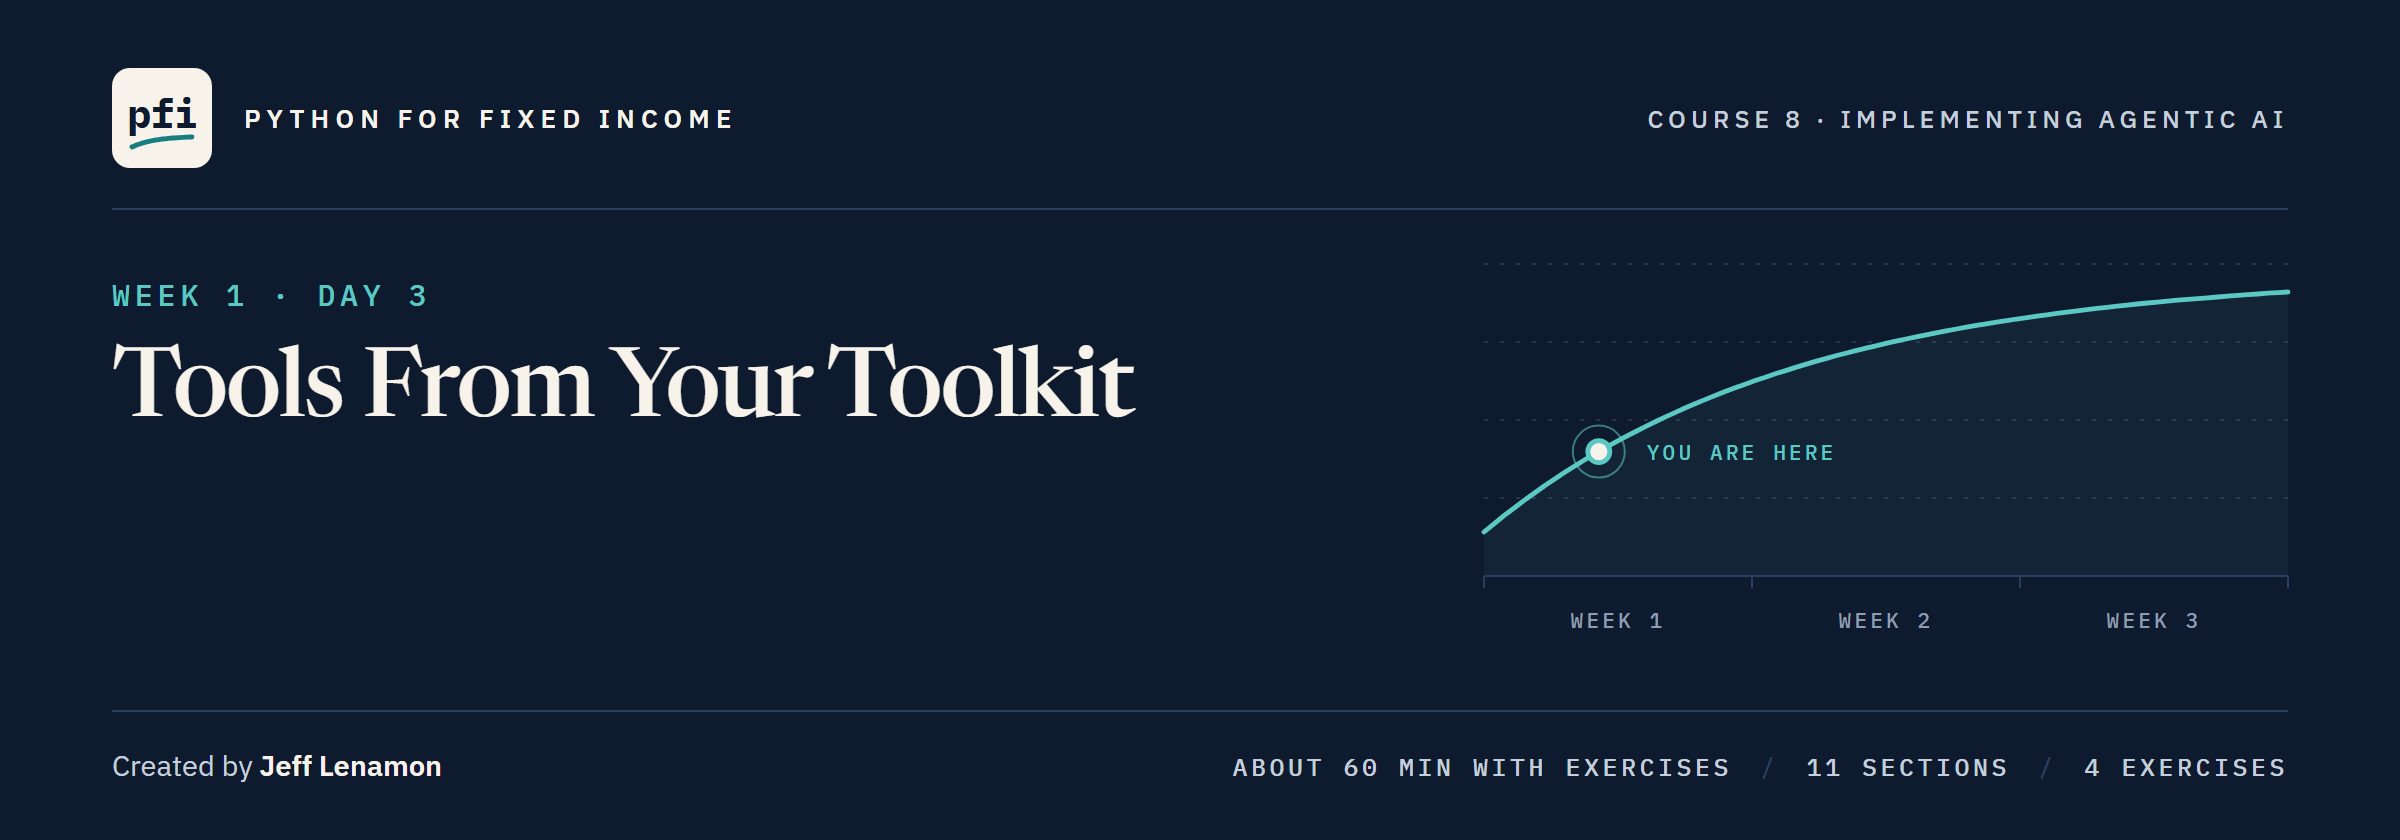

# Tools From Your Toolkit

Week 1, Day 3. Turn the desk's bond functions into tools whose descriptions are read from their own docstrings, offer seven at once, and check every argument before a tool runs.

**Data:** `holdings.csv`, 200 bonds as of 2026-09-30: **synthetic**, invented issuers and invented CUSIPs (Course 1), MIT with the code.

**Saved runs:** `course8_agent_runs/`, every request and response of the course's agent runs, recorded once on the author's key and replayed here without one.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day3/03_tools_from_your_toolkit.ipynb)

# Problem Statement

## Business Context

The desk asks bond questions about the book in plain words.
Days 1 and 2 offered one or two tools written as dictionaries by hand, and a dictionary can drift from the code it describes.
The desk now asks for Course 2's bond measures as tools, each described by its own function's signature and docstring.
Every argument is checked before a tool runs, and every result is kept short enough to resend.
Today's five bonds come from the synthetic book, chosen by CUSIP: invented issuers and invented CUSIPs.
Every reply was sent once by the course and saved, and the notebook replays it.

## Objectives

Write a bond function as a tool, with type hints and a docstring in units.
Build a tool's schema from its signature and docstring.
Offer several tools at once, and read which tool each saved run requested, with what arguments.
Follow one number through a run.
Test one change to a tool description.
Check a model's arguments against a tool's signature before the tool runs.
Measure what schemas and results add to a request, and clip a long result.

## Data Dictionary

`holdings.csv`, one row a bond of the synthetic book, as of 2026-09-30; the columns read today:

1. `cusip`, `issuer`: the bond's invented identifier and issuer
2. `coupon`: the annual coupon, in percent
3. `maturity`: the maturity date, YYYY-MM-DD
4. `price`, `accrued`: the clean price and the accrued interest, per 100 of face
5. `yield_pct`: the yield to maturity, in percent
6. `oas`: the option-adjusted spread, in bp
7. `duration`: the modified duration, in years
8. `market_value`: in US$
9. `as_of_date`: the date the book is as of

Each tool's result names its unit in its key: `clean_price_per_100`, `yield_pct`, `accrued_per_100`, `modified_duration_years`, `dv01_per_100`, `spread_duration_years`, `dts_years_bp`.
A run and its trace table are Day 2's.

## Your Route Through Day 3

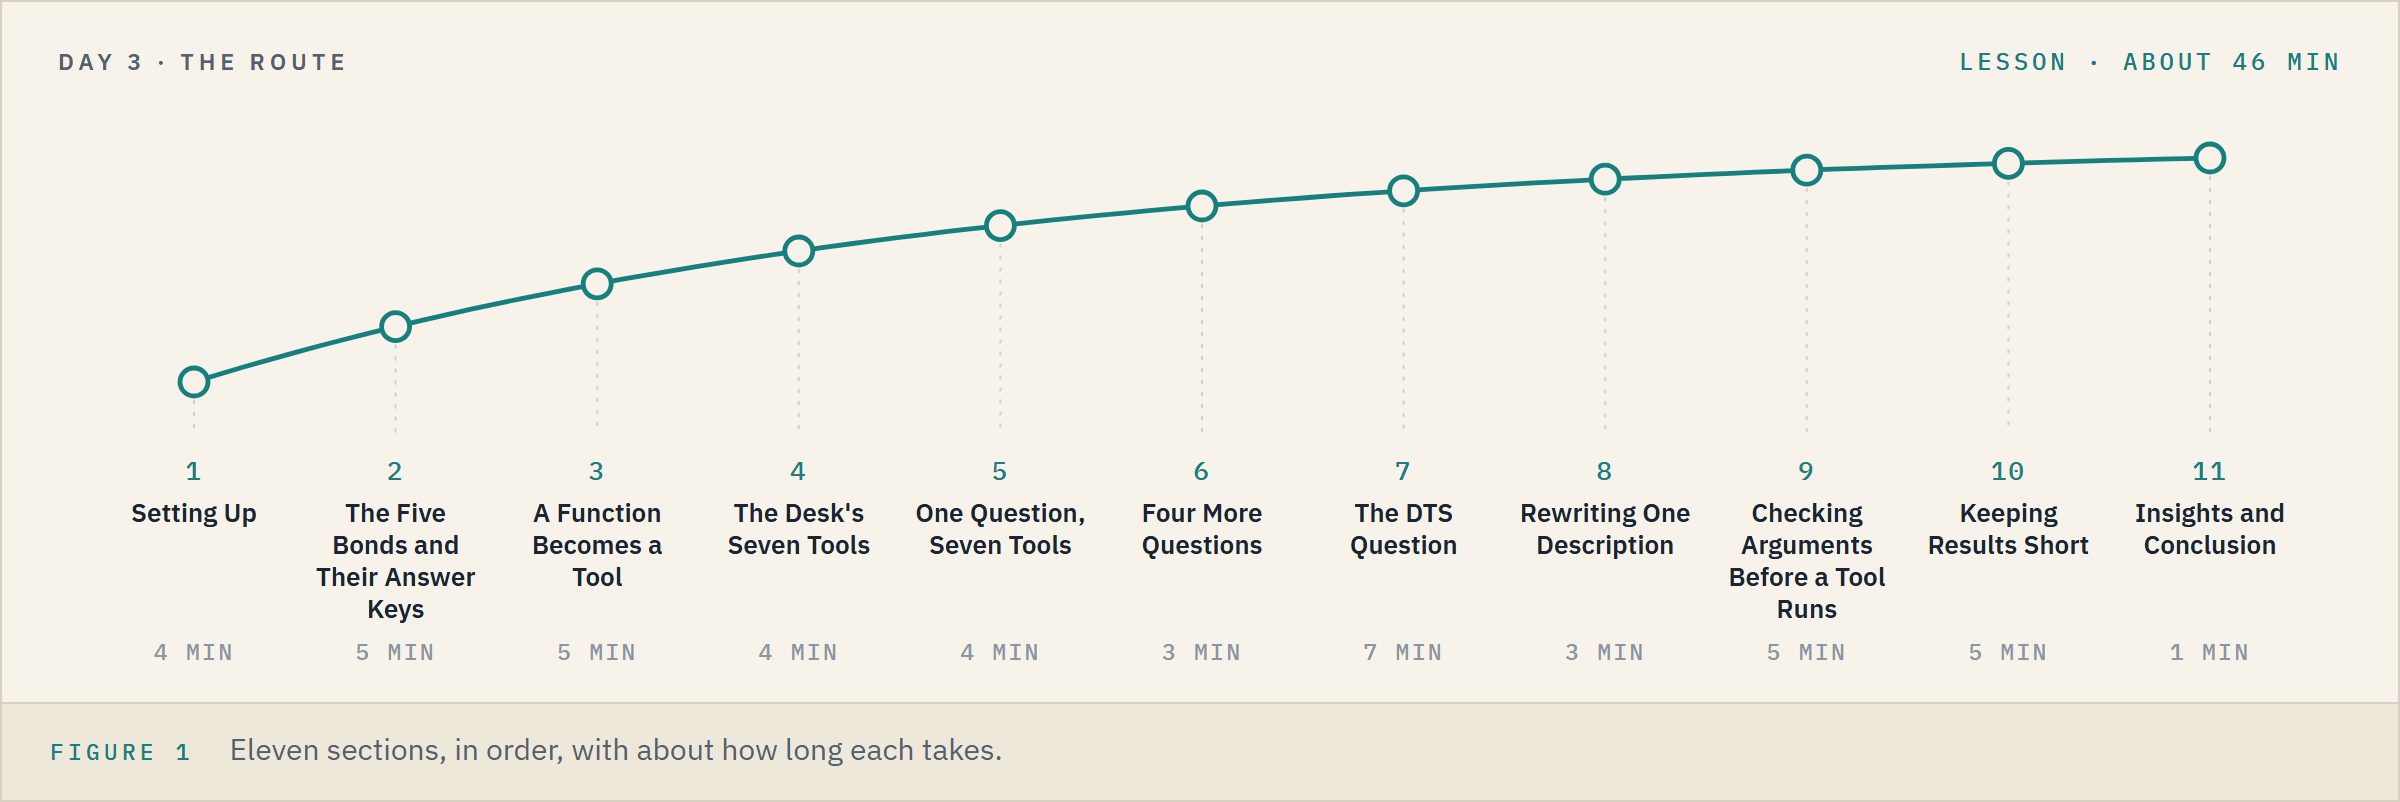

**Time.** About 46 minutes for the lesson, then about 12 for the four exercises.

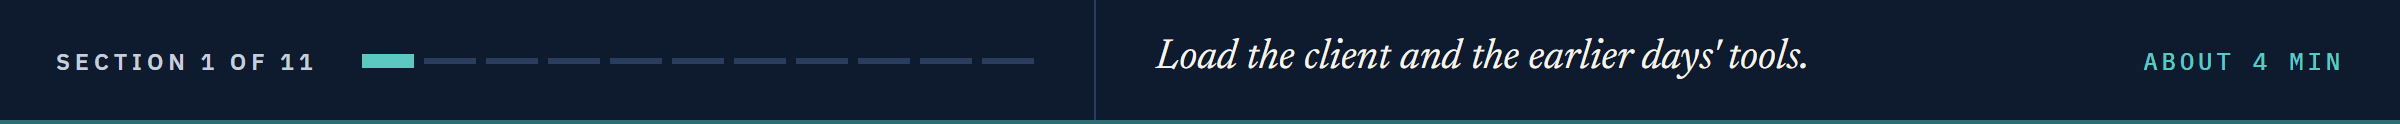

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# a function's signature and docstring read from Python itself (inspect), text as JSON, patterns, and dates
import inspect
import json
import re
from datetime import date

# to load and work with the data
import pandas as pd

# to draw charts, still and interactive
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## The Model, Live or Replayed

Day 1's client cell, with today's folder of saved runs.

In [3]:
# the model: with your own key each request goes to the model; without one, the course's saved runs answer it
import hashlib
import json
import sys

# Colab does not come with these: this installs them there (on your machine, requirements.txt already did)
if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install --quiet openai==3.26.0 python-dotenv==1.2.4")

import httpx2
from dotenv import dotenv_values
from openai import OpenAI

# today's saved runs: one file for each request the course sent, named by the request's fingerprint
RUNS = DATA + "course8_agent_runs/day03/"
MODEL = "gpt-4.1-mini"


def fingerprint(request):
    """The SHA-256 of a request's method, path and JSON body; never its headers, which carry the key."""
    text = json.dumps({"method": request.method, "path": request.url.path, "body": json.loads(request.content)},
                      sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(text.encode()).hexdigest()


def replay(request):
    """The saved response to exactly this request."""
    saved = pd.read_json(RUNS + fingerprint(request) + ".json", typ="series")
    return httpx2.Response(200, json=saved["response"])


# your own key, if you have one: an environment variable, my_bondmath\.env (Course 3), or Colab's Secrets panel
key = os.environ.get("OPENAI_API_KEY") or dotenv_values(Path.home() / "projects" / "my_bondmath" / ".env").get("OPENAI_API_KEY")
if not key and "google.colab" in sys.modules:
    from google.colab import userdata
    try:
        key = userdata.get("OPENAI_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        key = None

if key:
    client = OpenAI(api_key=key)
    MODE = "live"
else:
    saved_runs = httpx2.MockTransport(replay)
    client = OpenAI(api_key="replay", http_client=httpx2.Client(transport=saved_runs))
    MODE = "replay"
print(f"Mode: {MODE}.")

Mode: replay.


## The Tools From Earlier Days

Day 1's prompt is read from its saved first request; Day 2's `run_tools`, `agent_loop` and `trace_table` are repeated as written.

In [4]:
# Day 1's system prompt, as Day 1's saved first request carries it
day1_saved = pd.read_json(DATA + "course8_agent_runs/day01/17e1482ec8746857fa444b9bf058775eabe478af6df111aa120578eff9bd1fdd.json", typ="series")
DESK_PROMPT = day1_saved["request"]["messages"][0]["content"]
print(len(DESK_PROMPT), "characters")

1095 characters


In [5]:
# one tool message for each tool request: a tool that fails goes back to the model as words, never a number
def run_tools(assistant_message, tools):
    """Run each tool request of an assistant message and return one tool message for each."""
    tool_messages = []
    for tool_request in assistant_message["tool_calls"]:
        name = tool_request["function"]["name"]
        if name not in tools:
            tool_result = {"error": f"unknown tool {name}; the tools are {list(tools)}"}
        else:
            try:
                tool_result = tools[name](**json.loads(tool_request["function"]["arguments"]))
            except (TypeError, ValueError) as error:
                tool_result = {"error": str(error)}
        tool_messages.append({"role": "tool", "tool_call_id": tool_request["id"],
                              "content": json.dumps({"tool_call_id": tool_request["id"]} | tool_result, sort_keys=True)})
    return tool_messages

In [6]:
# the loop as a function: send, act, stop, with a step limit
def agent_loop(client, question, tools, schemas, max_steps=8):
    """Run a question until a reply holds text or max_steps requests are sent, and return the run."""
    messages = [{"role": "system", "content": DESK_PROMPT}, {"role": "user", "content": question}]
    body = {"model": MODEL, "tools": schemas, "temperature": 0, "seed": SEED, "max_tokens": 300,
            "parallel_tool_calls": False}
    replies = []
    for step in range(max_steps):
        request_body = body | {"messages": messages}
        reply = client.chat.completions.create(**request_body)
        replies.append(reply)
        message = reply.choices[0].message
        if not message.tool_calls:
            answer = {"role": "assistant", "content": message.content}
            return {"messages": messages + [answer], "replies": replies, "stop": "answer"}
        sent = {"role": "assistant", "content": None, "tool_calls": [t.model_dump(exclude_none=True) for t in message.tool_calls]}
        messages = messages + [sent] + run_tools(sent, tools)
    return {"messages": messages, "replies": replies, "stop": "max_steps"}

In [7]:
# a run as a table: one row a request, what its reply held, and what it cost in tokens
def trace_table(run):
    """One row per request of a run: the finish reason, the tool request and its result, and the tokens."""
    results = [m["content"] for m in run["messages"] if m["role"] == "tool"]
    rows = []
    for step, reply in enumerate(run["replies"], start=1):
        message = reply.choices[0].message
        row = {"step": step, "finish_reason": reply.choices[0].finish_reason, "tool": "", "arguments": "",
               "result": message.content or "", "prompt_tokens": reply.usage.prompt_tokens,
               "completion_tokens": reply.usage.completion_tokens}
        if message.tool_calls:
            row = row | {"tool": message.tool_calls[0].function.name, "arguments": message.tool_calls[0].function.arguments,
                         "result": results[step - 1]}
        rows.append(row)
    return pd.DataFrame(rows)

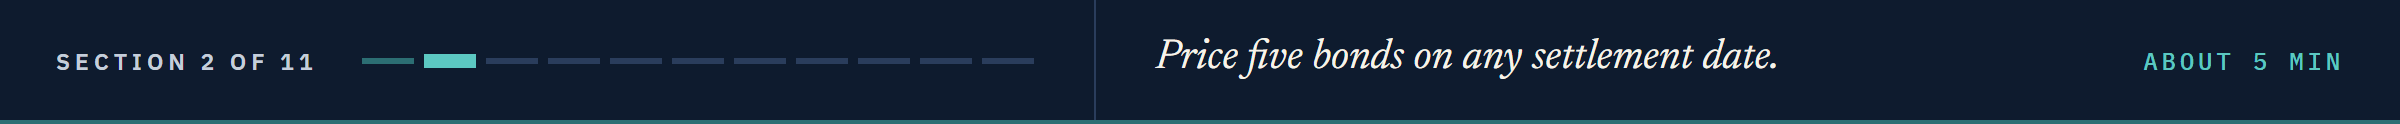

# The Five Bonds and Their Answer Keys

## Loading the Synthetic Book

In [8]:
# the desk's book: 200 bonds, synthetic (invented issuers and CUSIPs), as of 2026-09-30
holdings = pd.read_csv(DATA + "holdings.csv")
print(holdings.shape, "| as of", holdings["as_of_date"].max())

(200, 19) | as of 2026-09-30


## Five Bonds by CUSIP

In [9]:
# five bonds of the book, one or two for each of today's questions
CUSIPS = ["99080CAE8", "99039NAC0", "99034IAA0", "99126WAE0", "99033HAF2"]
five = holdings.set_index("cusip").loc[CUSIPS]
five[["issuer", "coupon", "maturity", "price", "accrued", "yield_pct", "oas", "duration"]]

,issuer,coupon,maturity,price,accrued,yield_pct,oas,duration
cusip,,,,,,,,
99080CAE8,Bezane Finance,7.000,2032-06-18,106.727,1.983,5.606,147,4.627
99039NAC0,Bezoquil Freight,5.125,2030-06-03,98.730,1.666,5.509,153,3.250
99034IAA0,Bezorin Finance,4.625,2038-09-17,88.692,0.167,5.960,155,8.846
99126WAE0,Bezimer Power,4.125,2029-07-16,98.979,0.848,4.516,62,2.588
99033HAF2,Clavane Foods,7.000,2050-02-26,107.310,0.661,6.393,183,11.770


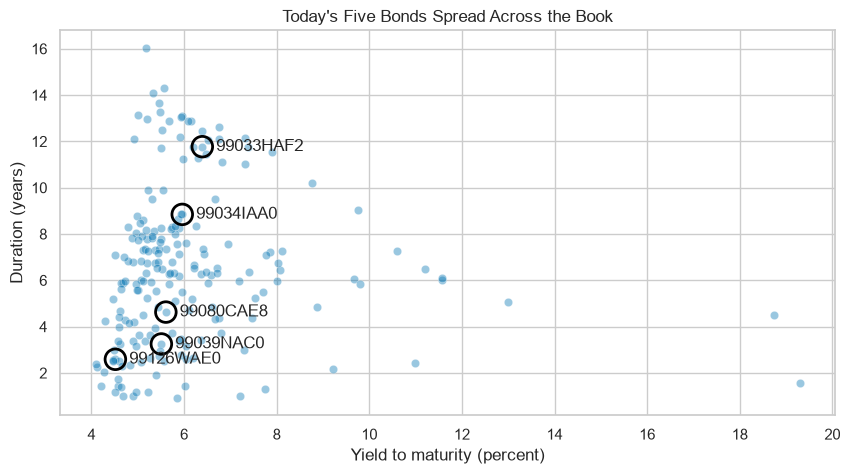

In [10]:
# the book's 200 bonds, duration against yield, today's five ringed and labelled
ax = sns.scatterplot(data=holdings, x="yield_pct", y="duration", alpha=0.4)
ax.scatter(five["yield_pct"], five["duration"], s=220, facecolors="none", edgecolors="black", lw=2)
for cusip, bond in five.iterrows():
    ax.text(bond["yield_pct"] + 0.3, bond["duration"], cusip, va="center")
ax.set_xlabel("Yield to maturity (percent)")
ax.set_ylabel("Duration (years)")
ax.set_title("Today's Five Bonds Spread Across the Book")
plt.show()

The five run from about 2.6 to 11.8 years of duration.

Every bond settles 2026-09-30, between two coupon dates: each carries accrued interest.

Day 1's `dv01` counted whole years of coupons, right only on a coupon date, so today's tools need Course 2's price on any date.

## The Coupon Period

`pd.DateOffset(months=6)` moves a date six months and keeps its day of the month.

In [11]:
# days accrued on 30/360 and coupons left: step back from maturity six months at a time (pd.Timestamp and .date(), Course 1)
def coupon_period(settlement, maturity):
    """Days accrued on 30/360 since the last coupon, and the number of coupons left."""
    settle, mature = date.fromisoformat(settlement), date.fromisoformat(maturity)
    coupons_left, previous = 0, mature
    while previous > settle:
        coupons_left = coupons_left + 1
        previous = (pd.Timestamp(mature) - pd.DateOffset(months=6 * coupons_left)).date()
    # Course 2's month-end and day-31 rules are left out: no maturity in the book falls on day 29 to 31
    days = 360 * (settle.year - previous.year) + 30 * (settle.month - previous.month) + settle.day - previous.day
    return days, coupons_left

In [12]:
# the latest day of the month any maturity in the book falls on, and bond 99080CAE8's coupon period
print("latest day:", pd.to_datetime(holdings["maturity"]).dt.day.max(), "| 99080CAE8:", coupon_period("2026-09-30", "2032-06-18"))

latest day: 28 | 99080CAE8: (102, 12)


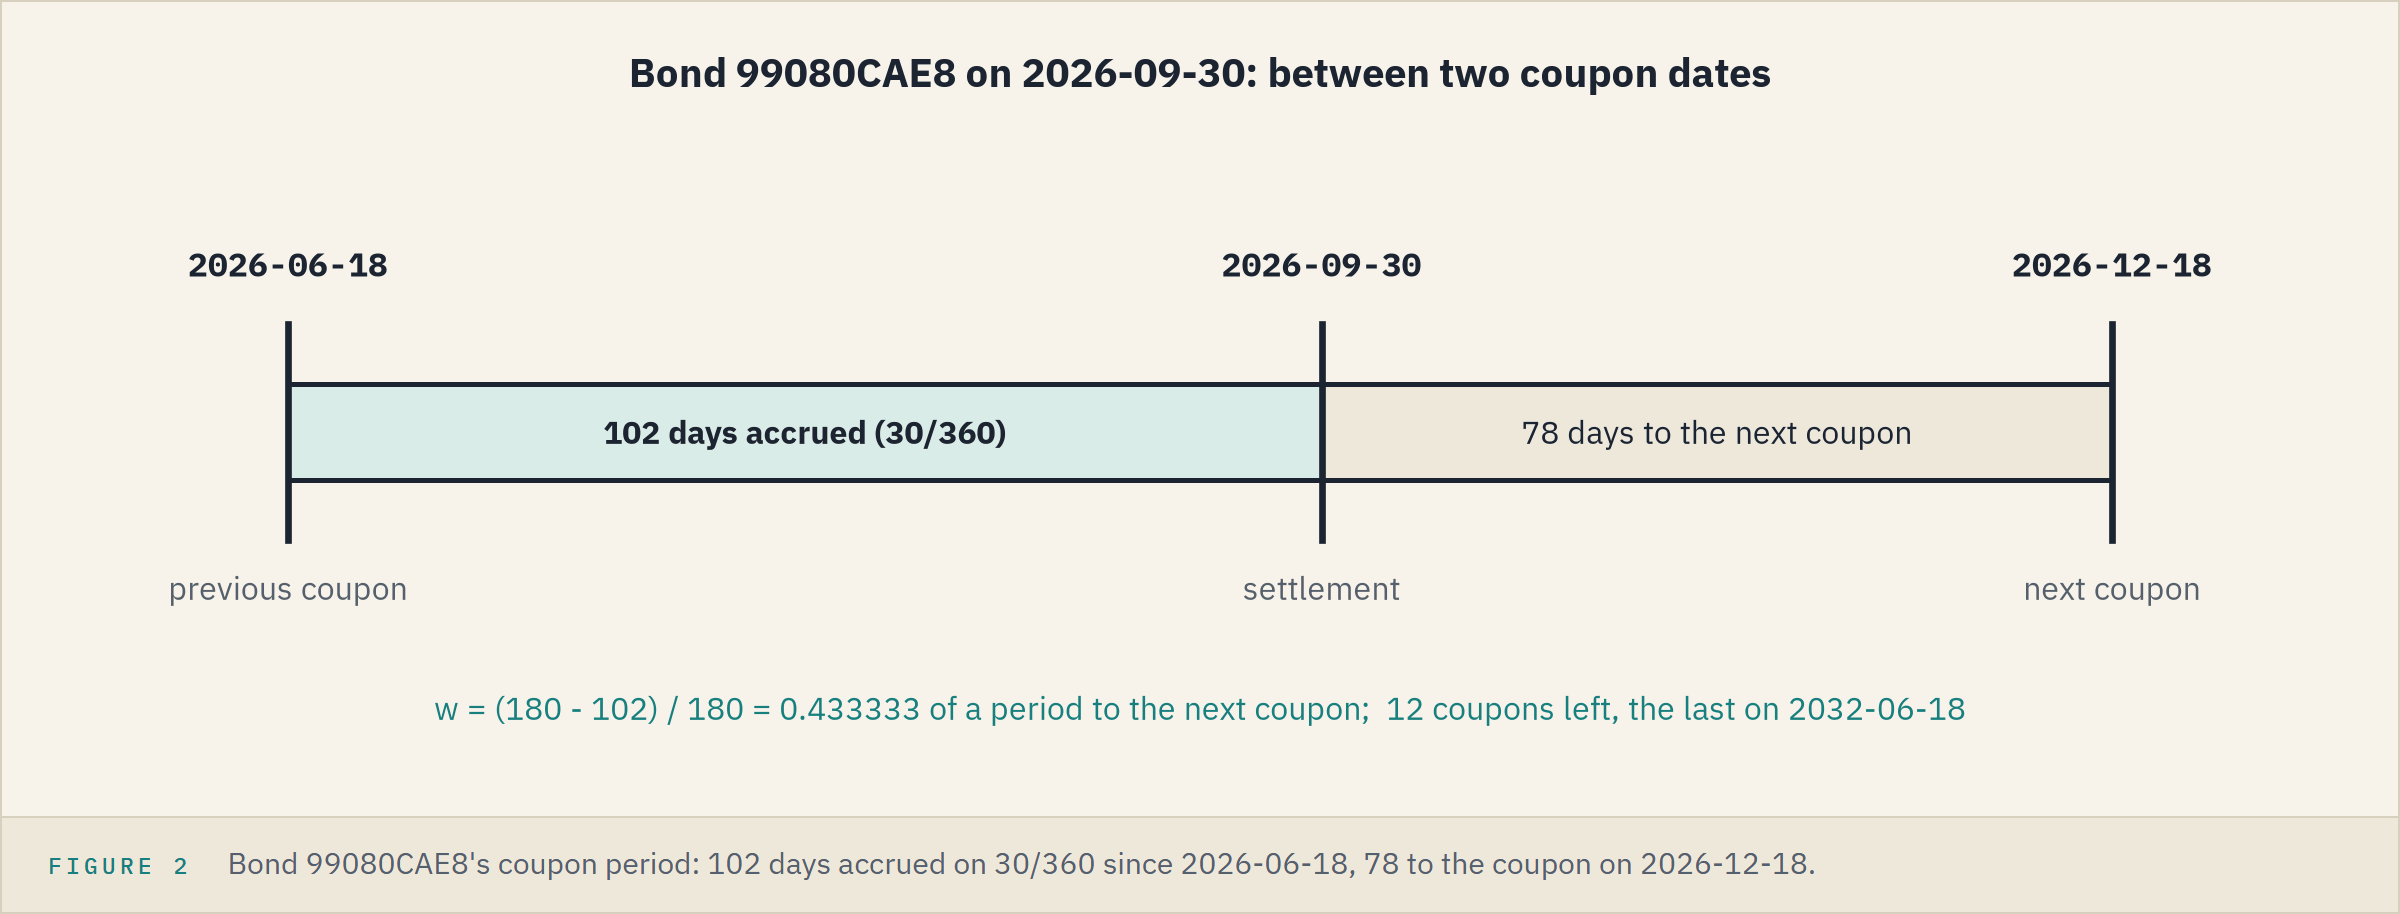

102 days accrued, 12 coupons left, the first of them 78 days away.

`w` is the part of a period to the next coupon: (180 - 102) / 180.

## Price and Accrued Interest on Any Date

In [13]:
# Course 2's price on any date: each flow discounted w + k periods
def dirty_price(settlement, maturity, coupon_pct, yield_pct):
    """The price per 100 of face with accrued interest, semiannual coupons, 30/360."""
    days, coupons_left = coupon_period(settlement, maturity)
    w = (180 - days) / 180
    flows = [coupon_pct / 2] * (coupons_left - 1) + [coupon_pct / 2 + 100]
    return sum(flow / (1 + yield_pct / 200) ** (w + k) for k, flow in enumerate(flows))


def accrued(settlement, maturity, coupon_pct):
    """The accrued interest per 100 of face: half the coupon times the days accrued over 180."""
    return coupon_pct / 2 * coupon_period(settlement, maturity)[0] / 180

In [14]:
# the five bonds by hand, rounded to the file's 3 decimals, beside the file's own columns
SETTLE = "2026-09-30"
hand = pd.DataFrame(index=five.index)
hand["accrued"] = [round(accrued(SETTLE, b.maturity, b.coupon), 3) for b in five.itertuples()]
hand["clean"] = [round(dirty_price(SETTLE, b.maturity, b.coupon, b.yield_pct) - accrued(SETTLE, b.maturity, b.coupon), 3)
                 for b in five.itertuples()]
print("equal to the file:", (hand.values == five[["accrued", "price"]].values).all(),
      "| the week's bond:", round(dirty_price("2026-10-02", "2031-10-02", 5.0, 5.06), 6))

equal to the file: True | the week's bond: 99.737845


All ten numbers match the file, and the week's bond still prices at Day 1's 99.737845 (a coupon date, so no accrued).

**The desk's own numbers are on the page before any tool exists.**

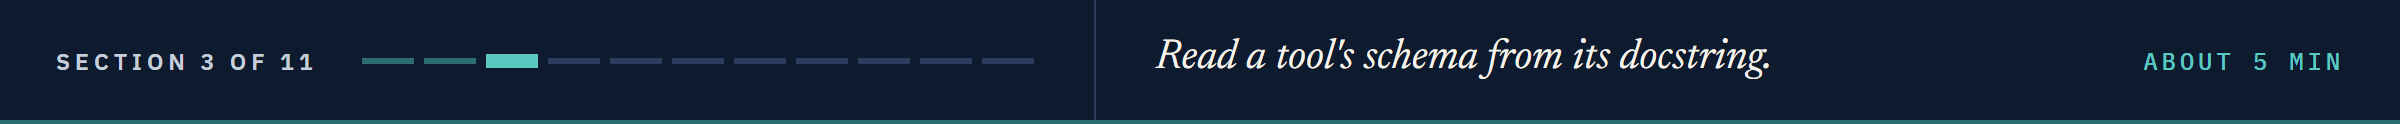

# A Function Becomes a Tool

## Type Hints and an Args Docstring

A **type hint** writes an argument's type after its name, `settlement: str`, and `-> dict` names the type returned.
Course 1 read them; here you write them for the first time.
The docstring's `Args:` block gives each argument one line: its name, a colon, and its description in units.

In [15]:
# the DV01 tool: a type hint on every argument, and a docstring the model will read
def dv01(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The DV01 in price points per 100 of face: the price change for a 1 bp fall in yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    # Day 1's Exercise 4: a coupon above 0 and below 0.5 can only be a decimal written by mistake
    if 0 < coupon_pct < 0.5:
        return {"error": f"coupon_pct {coupon_pct} is below 0.5: write the coupon in percent, 5.0 for a 5% coupon"}
    down = dirty_price(settlement, maturity, coupon_pct, yield_pct - 0.01)
    up = dirty_price(settlement, maturity, coupon_pct, yield_pct + 0.01)
    return {"dv01_per_100": round((down - up) / 2, 6)}

In [16]:
# the week's bond (Day 1's answer key), then bond 99033HAF2 of the book
print(dv01("2026-10-02", "2031-10-02", 5.0, 5.06))
print(dv01(SETTLE, "2050-02-26", 7.0, 6.393))

{'dv01_per_100': 0.043625}
{'dv01_per_100': 0.127083}


Day 1's 0.043625, now from Course 2's price on any date.

Python never checks a hint: it is there to be read, by you and, next, by `tool_schema`.

## The Schema Read From the Docstring

`inspect` reads a function from Python itself: `inspect.getdoc` gives its docstring, and `inspect.signature(function).parameters` its parameters by name, in order.

In [17]:
# the JSON schema type each type hint becomes
TYPES = {str: "string", float: "number"}


def tool_schema(function):
    """A tool's schema read from a function's name, signature and docstring."""
    lines = inspect.getdoc(function).splitlines()
    described = {}
    # each line after Args: split at its first ": " (the 1 in split) into a name and a description
    for line in lines[lines.index("Args:") + 1:]:
        name, words = line.strip().split(": ", 1)
        described[name] = words
    # .annotation is a parameter's type hint
    parameters = inspect.signature(function).parameters
    properties = {name: {"type": TYPES[p.annotation], "description": described[name]} for name, p in parameters.items()}
    return {"type": "function", "function": {
        "name": function.__name__, "description": lines[0], "strict": True,
        "parameters": {"type": "object", "properties": properties, "required": list(parameters),
                       "additionalProperties": False}}}

In [18]:
# dv01's schema, printed as JSON with one space of indent a level
print(json.dumps(tool_schema(dv01), indent=1))

{
 "type": "function",
 "function": {
  "name": "dv01",
  "description": "The DV01 in price points per 100 of face: the price change for a 1 bp fall in yield.",
  "strict": true,
  "parameters": {
   "type": "object",
   "properties": {
    "settlement": {
     "type": "string",
     "description": "the settlement date as YYYY-MM-DD, for example 2026-10-02."
    },
    "maturity": {
     "type": "string",
     "description": "the maturity date as YYYY-MM-DD."
    },
    "coupon_pct": {
     "type": "number",
     "description": "the annual coupon in percent, 5.0 for a 5% coupon."
    },
    "yield_pct": {
     "type": "number",
     "description": "the yield to maturity in percent, 5.06 for 5.06%."
    }
   },
   "required": [
    "settlement",
    "maturity",
    "coupon_pct",
    "yield_pct"
   ],
   "additionalProperties": false
  }
 }
}


## Day 1's Schema, Written by Hand

In [19]:
# Day 1's DV01_TOOL as its saved first request carries it, against the schema read from the docstring
print("read from the docstring, equal to Day 1's by hand:", tool_schema(dv01) == day1_saved["request"]["tools"][0])

read from the docstring, equal to Day 1's by hand: True


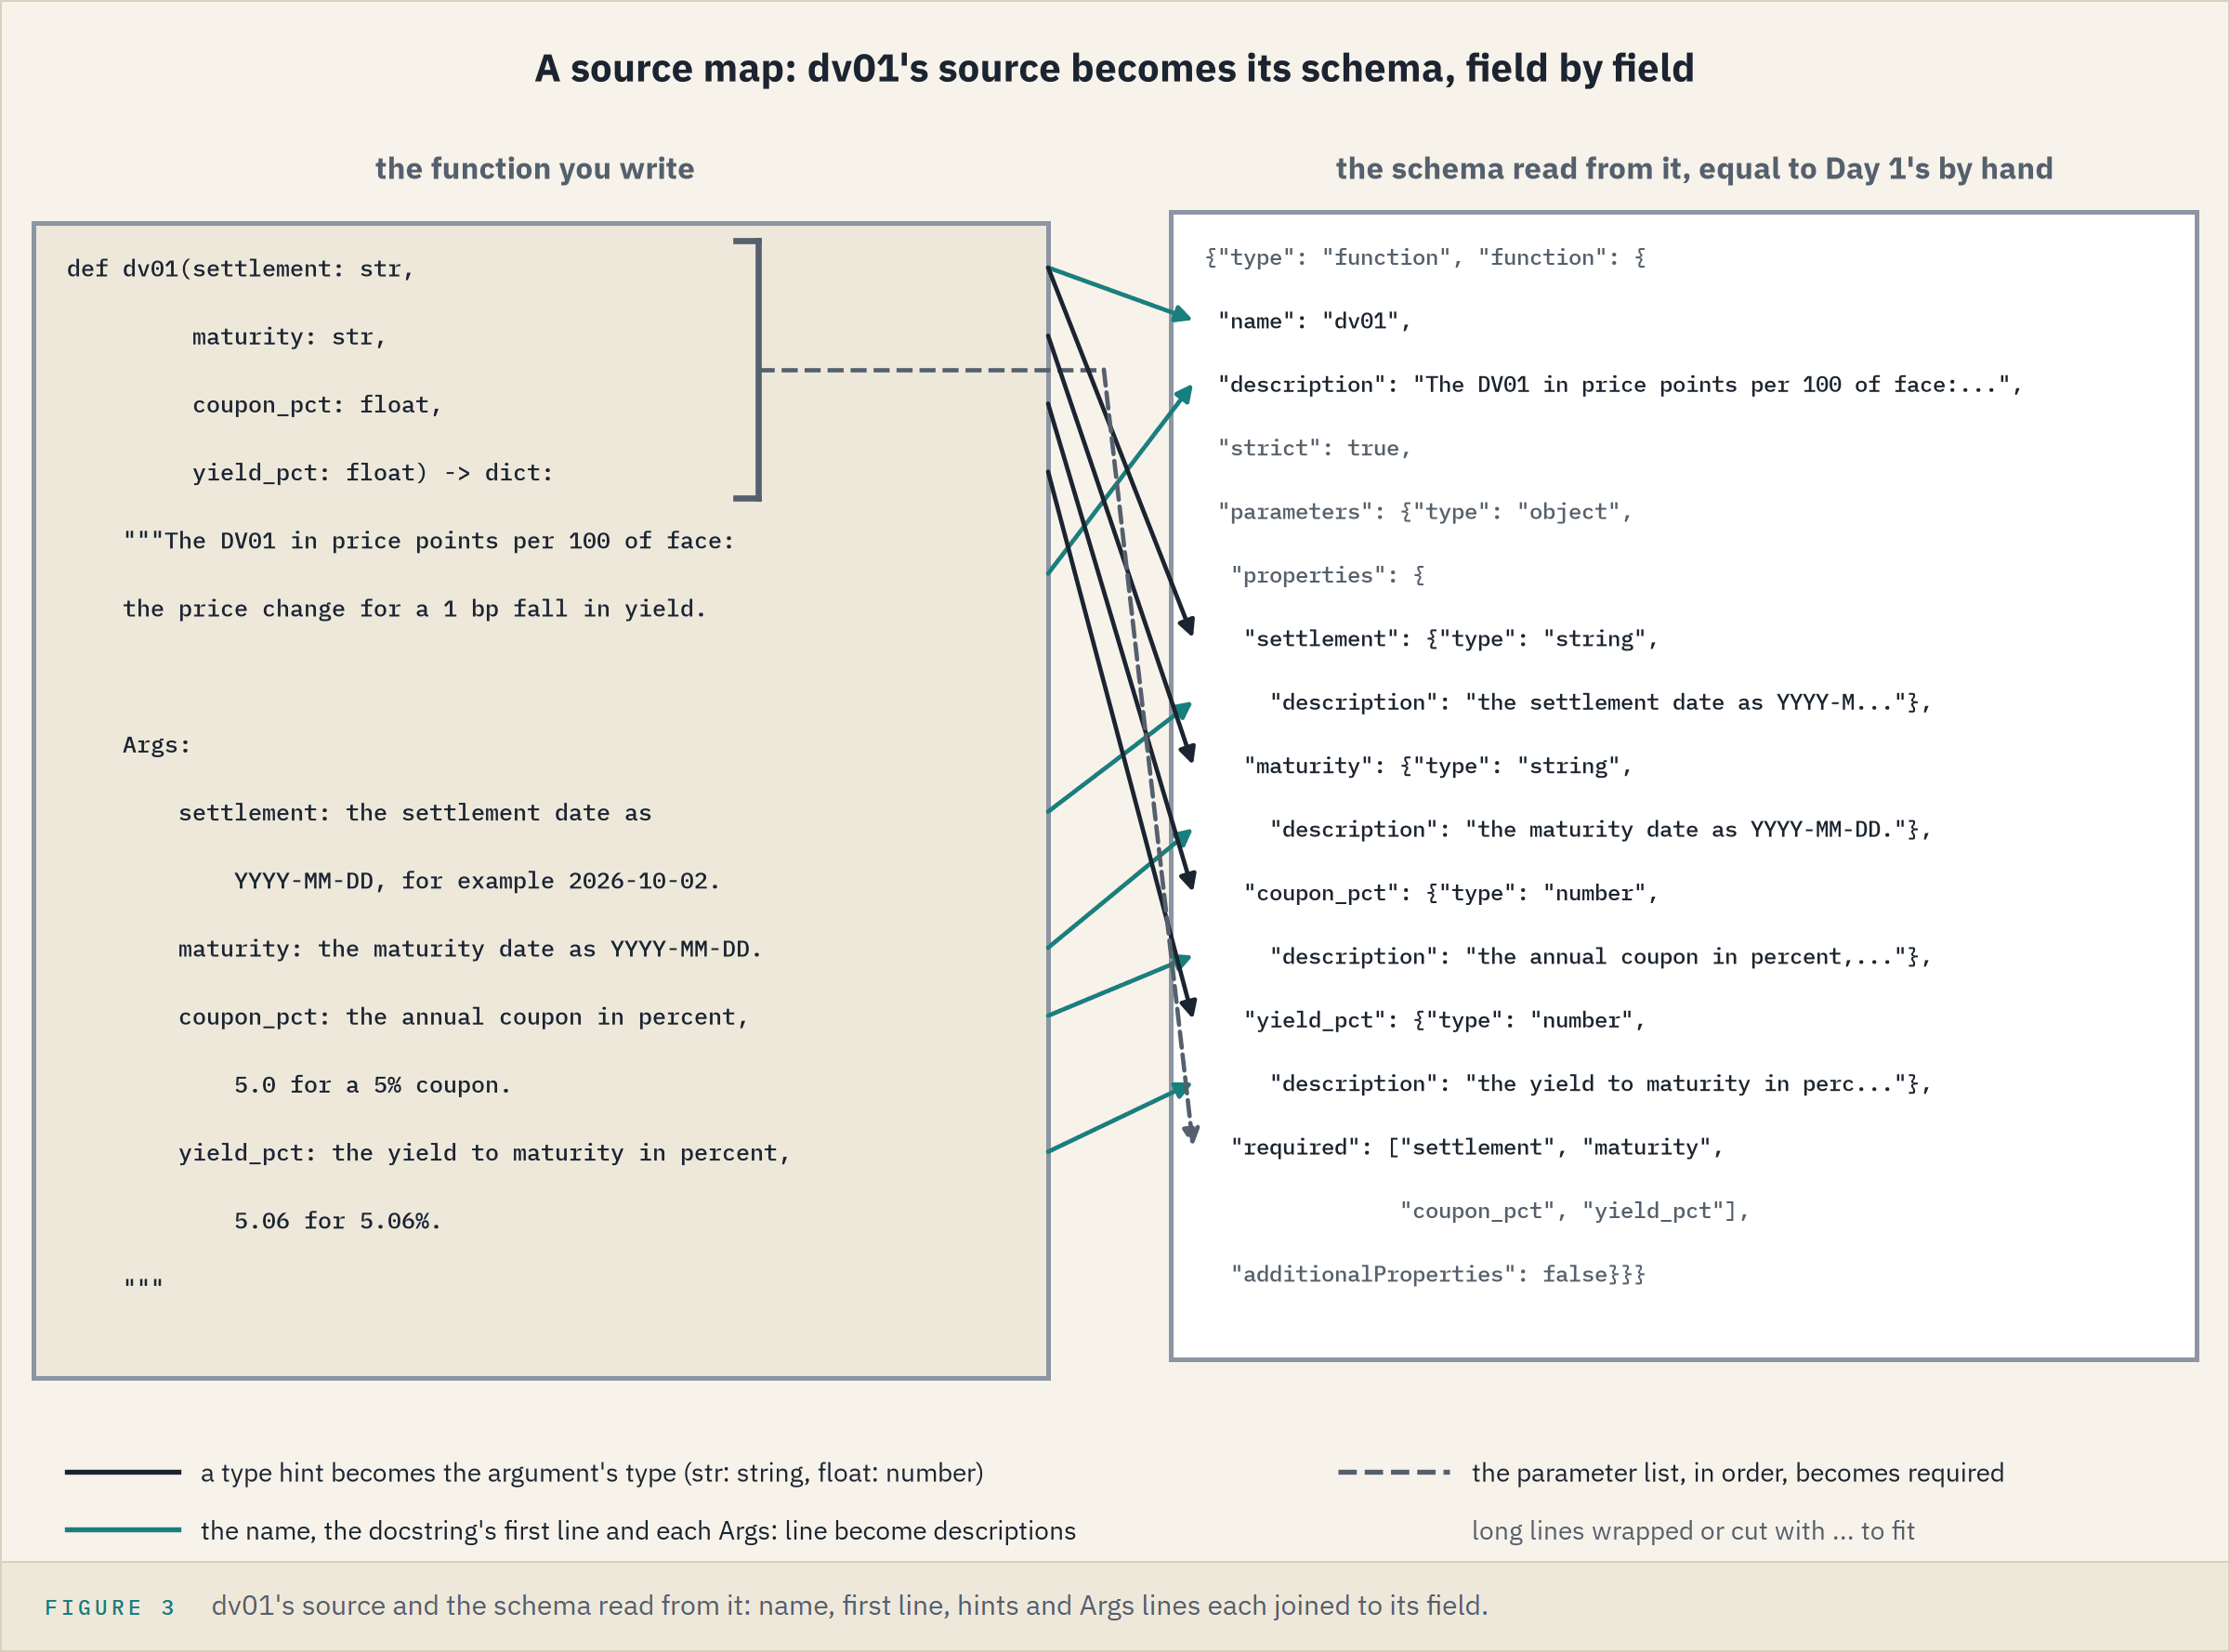

A **source map** joins each piece of a source to what it becomes.

The name, the first line, the four hints and the four `Args:` lines fill every field Day 1 typed by hand.

### Interpretation of the Source Map

Nothing in the schema is typed twice: change the docstring and the schema changes with it.

The function's body never reaches the request, so the schema says nothing about how the DV01 is computed.

**One signature and one docstring serve the code and the model, so the description cannot drift from the function.**

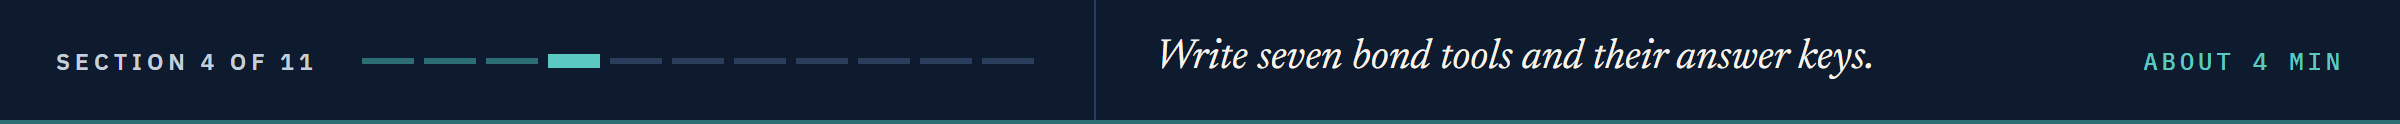

# The Desk's Seven Tools

## Price, Yield and Accrued Interest

Each tool keeps the docstring the course's saved runs were recorded with, word for word.

In [20]:
# the clean price: the dirty price less the accrued interest
def price(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The clean price per 100 of face of a fixed-coupon bond (semiannual coupons, 30/360), from its yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    clean = dirty_price(settlement, maturity, coupon_pct, yield_pct) - accrued(settlement, maturity, coupon_pct)
    return {"clean_price_per_100": round(clean, 6)}

In [21]:
# Course 2's bisection: price the middle of the bracket, keep the half that holds the quoted price
def yield_to_maturity(settlement: str, maturity: str, coupon_pct: float, clean_price: float) -> dict:
    """The yield to maturity in percent of a fixed-coupon bond (semiannual coupons, 30/360), from its clean price.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        clean_price: the clean price per 100 of face, for example 99.74.
    """
    low, high = -5.0, 100.0
    while high - low > 1e-10:
        middle = (low + high) / 2
        # the clean price unrounded: the price tool's 6 decimals would move 99080CAE8's yield from 5.605920 to 5.605919
        if dirty_price(settlement, maturity, coupon_pct, middle) - accrued(settlement, maturity, coupon_pct) > clean_price:
            low = middle
        else:
            high = middle
    return {"yield_pct": round((low + high) / 2, 6)}

In [22]:
# the accrued interest, rounded as every tool rounds, to 6 decimals
def accrued_interest(settlement: str, maturity: str, coupon_pct: float) -> dict:
    """The accrued interest per 100 of face the buyer pays the seller (semiannual coupons, 30/360).

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
    """
    return {"accrued_per_100": round(accrued(settlement, maturity, coupon_pct), 6)}

## Duration, Spread Duration and DTS

In [23]:
# Course 2's bump: 1 bp each way on the dirty price, the change per 100 bp as a share of the dirty price
def modified_duration(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The modified duration in years: the percent price change for a 100 bp change in yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    down = dirty_price(settlement, maturity, coupon_pct, yield_pct - 0.01)
    up = dirty_price(settlement, maturity, coupon_pct, yield_pct + 0.01)
    full = dirty_price(settlement, maturity, coupon_pct, yield_pct)
    return {"modified_duration_years": round((down - up) / 0.0002 / full, 6)}

In [24]:
# a spread move is a yield move for a fixed-coupon bullet, so its spread duration is its modified duration (Course 2)
def spread_duration(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The spread duration in years: the percent price change for a 100 bp move in the spread.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    years = modified_duration(settlement, maturity, coupon_pct, yield_pct)["modified_duration_years"]
    return {"spread_duration_years": years}


# DTS: spread duration times spread, in years times bp (Course 2)
def dts(spread_duration_years: float, spread_bp: float) -> dict:
    """Duration times spread (DTS) in years times bp: spread duration in years times the spread in bp.

    Args:
        spread_duration_years: the spread duration in years, for example 4.627.
        spread_bp: the spread in basis points, for example 147.
    """
    return {"dts_years_bp": round(spread_duration_years * spread_bp, 6)}

## The Toolkit

In [25]:
# the toolkit: each tool under its name, in the order every request lists them; then each schema read from its docstring
TOOLS = {f.__name__: f for f in (price, yield_to_maturity, accrued_interest, modified_duration, dv01, spread_duration, dts)}
SCHEMAS = [tool_schema(f) for f in TOOLS.values()]
for schema in SCHEMAS:
    print(schema["function"]["name"], "|", schema["function"]["description"])

price | The clean price per 100 of face of a fixed-coupon bond (semiannual coupons, 30/360), from its yield.
yield_to_maturity | The yield to maturity in percent of a fixed-coupon bond (semiannual coupons, 30/360), from its clean price.
accrued_interest | The accrued interest per 100 of face the buyer pays the seller (semiannual coupons, 30/360).
modified_duration | The modified duration in years: the percent price change for a 100 bp change in yield.
dv01 | The DV01 in price points per 100 of face: the price change for a 1 bp fall in yield.
spread_duration | The spread duration in years: the percent price change for a 100 bp move in the spread.
dts | Duration times spread (DTS) in years times bp: spread duration in years times the spread in bp.


Seven names and seven first lines: all the model reads of each tool, with its `Args:` lines.

Replay checks them to the character: a schema one character off changes the fingerprint, and no saved file answers it (Day 1).

## The Answer Keys

In [26]:
# every tool on the five bonds: the answer keys, before any request
keys = pd.DataFrame(index=five.index)
keys["price"] = [price(SETTLE, b.maturity, b.coupon, b.yield_pct)["clean_price_per_100"] for b in five.itertuples()]
keys["yield"] = [yield_to_maturity(SETTLE, b.maturity, b.coupon, b.price)["yield_pct"] for b in five.itertuples()]
keys["accrued"] = [accrued_interest(SETTLE, b.maturity, b.coupon)["accrued_per_100"] for b in five.itertuples()]
keys["duration"] = [modified_duration(SETTLE, b.maturity, b.coupon, b.yield_pct)["modified_duration_years"] for b in five.itertuples()]
keys["dv01"] = [dv01(SETTLE, b.maturity, b.coupon, b.yield_pct)["dv01_per_100"] for b in five.itertuples()]
keys["dts"] = [dts(keys.loc[b.Index, "duration"], b.oas)["dts_years_bp"] for b in five.itertuples()]
keys

,price,yield,accrued,duration,dv01,dts
cusip,,,,,,
99080CAE8,106.726595,5.605920,1.983333,4.626971,0.050300,680.164737
99039NAC0,98.730160,5.509049,1.665625,3.249883,0.032627,497.232099
99034IAA0,88.692370,5.960047,0.167014,8.846338,0.078608,1371.182390
99126WAE0,98.978653,4.515866,0.847917,2.587515,0.025830,160.425930
99033HAF2,107.309586,6.392967,0.661111,11.770127,0.127083,2153.933241


Each question today asks one bond for one measure: price and DTS of 99080CAE8, yield of 99039NAC0, accrued of 99034IAA0, duration of 99126WAE0, DV01 of 99033HAF2.

The yield column inverts the file's price rounded to 3 decimals, so 99080CAE8 gives 5.605920 against the file's 5.606.

**The tools compute; the request carries only their schemas.**

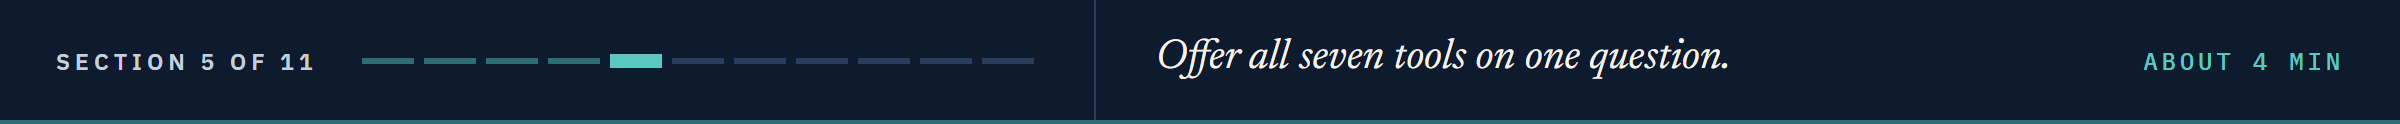

# One Question, Seven Tools

## The Six Questions

In [27]:
# the desk's six questions, one measure of one bond each, worded as the course recorded them
QUESTIONS = {
    "price": "As of 2026-09-30, what is the clean price per 100 of face of bond 99080CAE8 of the synthetic holdings, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield?",
    "yield": "As of 2026-09-30, what is the yield to maturity in percent of bond 99039NAC0 of the synthetic holdings, a 5.125% bullet settling 2026-09-30 and maturing 2030-06-03 at a clean price of 98.730 per 100 of face?",
    "accrued": "As of 2026-09-30, what is the accrued interest per 100 of face of bond 99034IAA0 of the synthetic holdings, a 4.625% bullet settling 2026-09-30 and maturing 2038-09-17?",
    "duration": "As of 2026-09-30, what is the modified duration in years, the percent price change for a 100 bp change in yield, of bond 99126WAE0 of the synthetic holdings, a 4.125% bullet settling 2026-09-30 and maturing 2029-07-16 at a 4.516% yield?",
    "dv01": "As of 2026-09-30, what is the DV01 per 100 of face, the price change for a 1 bp fall in yield, of bond 99033HAF2 of the synthetic holdings, a 7.000% bullet settling 2026-09-30 and maturing 2050-02-26 at a 6.393% yield?",
    "dts": "As of 2026-09-30, what is the DTS, the spread duration in years times the spread in bp, of bond 99080CAE8 of the synthetic holdings, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield and an OAS of 147 bp?"}

**Predict 1**

Day 1's first request offered one tool and carried 432 prompt tokens.
The price question's first request offers all seven.
Q. How many prompt tokens does it carry? Write down a number.

## Seven Tools Offered

In [28]:
# the price question with all seven tools offered and wired
run_price = agent_loop(client, QUESTIONS["price"], TOOLS, SCHEMAS)
print(trace_table(run_price)[["step", "finish_reason", "tool", "arguments", "prompt_tokens"]].to_string(index=False))

 step finish_reason  tool                                                                            arguments  prompt_tokens
    1    tool_calls price {"settlement":"2026-09-30","maturity":"2032-06-18","coupon_pct":7,"yield_pct":5.606}           1062
    2          stop                                                                                                      1149


In [29]:
# agent answer
print(run_price["replies"][-1].choices[0].message.content)

As of 2026-09-30, the clean price per 100 of face of bond 99080CAE8, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield, is 106.7266.


Of seven tools, the first tool request named `price`, the one the question needs, on the question's own terms.

The coupon came as the integer 7, as Day 1's came as 5.

106.7266 is the answer key, 106.726595, at 4 decimals.

1,062 prompt tokens against Day 1's 432: check your Predict 1.

**Seven tools on offer, and the saved run requested the one the question needs.**

## What Every Request Carries

In [30]:
# the first request's characters by part: the prompt and question as text, each schema as JSON text (Day 1's measure)
schema_chars = pd.Series({schema["function"]["name"]: len(json.dumps(schema)) for schema in SCHEMAS})
parts = pd.Series({"desk prompt": len(DESK_PROMPT), "question": len(QUESTIONS["price"]), "seven schemas": schema_chars.sum()})
print(schema_chars.to_dict())
print(parts.to_dict(), "| the schemas' share:", round(parts["seven schemas"] / parts.sum() * 100, 1), "percent")

{'price': 732, 'yield_to_maturity': 757, 'accrued_interest': 621, 'modified_duration': 730, 'dv01': 715, 'spread_duration': 729, 'dts': 520}
{'desk prompt': 1095, 'question': 181, 'seven schemas': 4804} | the schemas' share: 79.0 percent


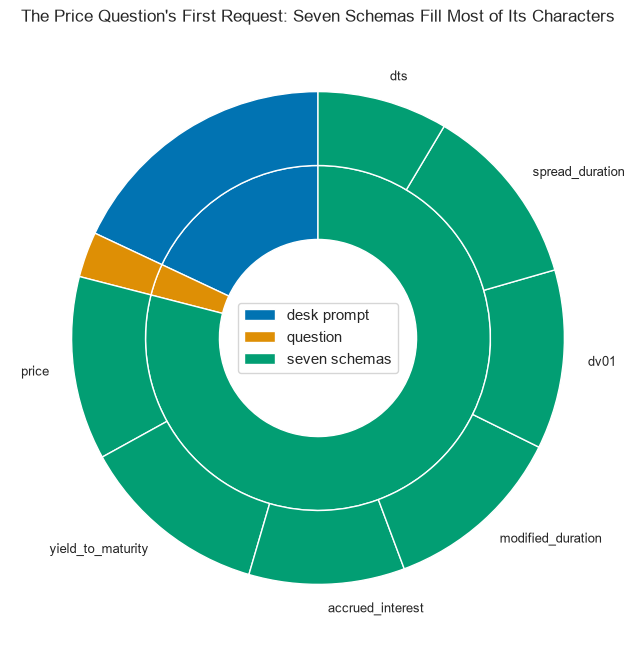

In [31]:
# a sunburst (Course 7's Day 3): two rings by ax.pie with wedgeprops width (Course 4's Day 13 donut); pie returns the wedges first
fig, ax = plt.subplots(figsize=(8, 8))
ring = {"width": 0.3, "edgecolor": "white"}
inner = ax.pie(parts, radius=0.7, wedgeprops=ring, startangle=90, colors=sns.color_palette()[:3])[0]
outer = pd.concat([parts[["desk prompt", "question"]], schema_chars])
ax.pie(outer, radius=1.0, labels=[""] * 2 + list(schema_chars.index), wedgeprops=ring, startangle=90,
       colors=sns.color_palette()[:2] + [sns.color_palette()[2]] * 7, textprops={"fontsize": 9})
ax.legend(inner, parts.index, loc="center")
ax.set_title("The Price Question's First Request: Seven Schemas Fill Most of Its Characters")
plt.show()

Inside, the three parts; outside, the seven schemas one by one, `dts` the shortest with two arguments.

The schemas ride in every request of every run, whether the question needs them or not.

**Every tool offered is paid for in every request.**

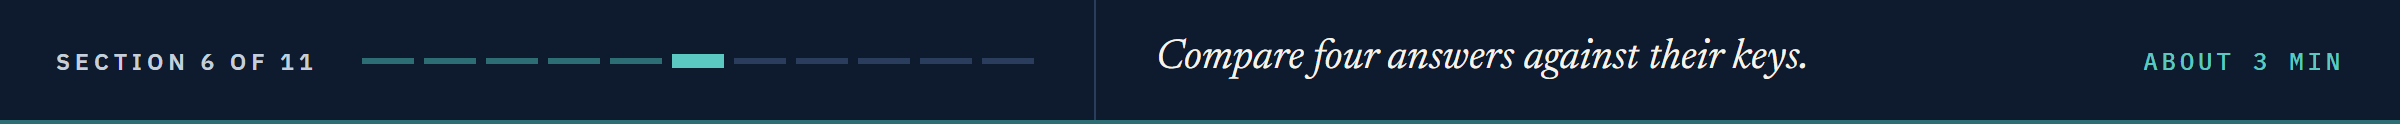

# Four More Questions

**Predict 2**

The price answer wrote 106.7266: its tool's value to 4 of its 6 decimals.
The next four questions ask for a yield, accrued interest, a duration and a DV01.
Q. Of the five answers, the price answer included, how many write the tool's value with all 6 decimals? Write down a number.

## Yield, Accrued Interest, Duration and DV01

In [32]:
# the four questions in turn, each run kept under its name; one line each: the first tool request
runs = {"price": run_price}
for name in ["yield", "accrued", "duration", "dv01"]:
    runs[name] = agent_loop(client, QUESTIONS[name], TOOLS, SCHEMAS)
    print(name, "|", trace_table(runs[name])["tool"][0], trace_table(runs[name])["arguments"][0])

yield | yield_to_maturity {"settlement":"2026-09-30","maturity":"2030-06-03","coupon_pct":5.125,"clean_price":98.73}
accrued | accrued_interest {"settlement":"2026-09-30","maturity":"2038-09-17","coupon_pct":4.625}
duration | modified_duration {"settlement":"2026-09-30","maturity":"2029-07-16","coupon_pct":4.125,"yield_pct":4.516}
dv01 | dv01 {"settlement":"2026-09-30","maturity":"2050-02-26","coupon_pct":7,"yield_pct":6.393}


In [33]:
# agent answer
for name in ["yield", "accrued", "duration", "dv01"]:
    print(runs[name]["replies"][-1].choices[0].message.content)

As of 2026-09-30, the yield to maturity of bond 99039NAC0, a 5.125% bullet settling on 2026-09-30 and maturing on 2030-06-03, at a clean price of 98.730 per 100 of face, is approximately 5.509% (call_Ns1pISJSkZDxsBBjhDOWKCML).
As of 2026-09-30, the accrued interest per 100 of face of bond 99034IAA0, a 4.625% bullet settling 2026-09-30 and maturing 2038-09-17, is 0.167014.
As of 2026-09-30, the modified duration in years, the percent price change for a 100 bp change in yield, of bond 99126WAE0, a 4.125% bullet settling 2026-09-30 and maturing 2029-07-16 at a 4.516% yield, is approximately 2.588 years.
As of 2026-09-30, the DV01 per 100 of face, the price change for a 1 bp fall in yield, of bond 99033HAF2, a 7.000% bullet settling 2026-09-30 and maturing 2050-02-26 at a 6.393% yield, is 0.127083. (call_SGeBarWguVBJLj7faeZp1Ql3)


In each run the first tool request named the tool its question needs, on the question's terms.

The yield run sent the quoted price, 98.73, as `clean_price`: the one tool whose fourth argument is not a yield.

## The Answers Against the Keys

In [34]:
# each run's tool value and the answer's number nearest to it (Day 1's pattern; min with key= as sorted takes it)
rows = []
for name, run in runs.items():
    value = [v for k, v in json.loads(run["messages"][-2]["content"]).items() if k != "tool_call_id"][0]
    answer = run["replies"][-1].choices[0].message.content
    written = min(re.findall(r"\b\d+\.\d+", answer), key=lambda number: abs(float(number) - value))
    rows.append({"run": name, "tool_value": value, "written": written, "decimals": len(written.split(".")[1])})
rounding = pd.DataFrame(rows).set_index("run")
rounding

,tool_value,written,decimals
run,,,
price,106.726595,106.7266,4
yield,5.509049,5.509,3
accrued,0.167014,0.167014,6
duration,2.587515,2.588,3
dv01,0.127083,0.127083,6


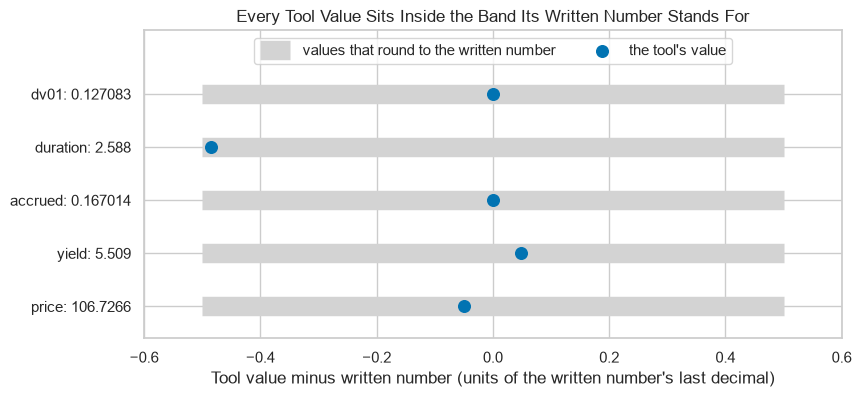

In [35]:
# each written number stands for the band of values that round to it, drawn at one width; the tool's value a dot
rounding["offset"] = (rounding["tool_value"] - rounding["written"].astype(float)) * 10.0 ** rounding["decimals"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hlines(range(5), -0.5, 0.5, lw=14, color="lightgrey", label="values that round to the written number")
ax.scatter(rounding["offset"], range(5), s=70, zorder=3, label="the tool's value")
ax.set_yticks(range(5), [f"{name}: {number}" for name, number in rounding["written"].items()])
ax.set_xlim(-0.6, 0.6)
ax.set_ylim(-0.6, 5.2)
ax.set_xlabel("Tool value minus written number (units of the written number's last decimal)")
ax.set_title("Every Tool Value Sits Inside the Band Its Written Number Stands For")
ax.legend(loc="upper center", ncols=2)
plt.show()

### Interpretation of the Rounding

Two of five answers write the tool's value whole, 0.167014 and 0.127083: check your Predict 2.

Three round it, to 4 or 3 decimals, and two of those say "approximately".

Every dot sits inside its band, so no digit is wrong.

Yet the desk's prompt says never state a number that no tool returned, and 2.588 is not a number `modified_duration` returned.

**Day 4 writes that rule as code.**

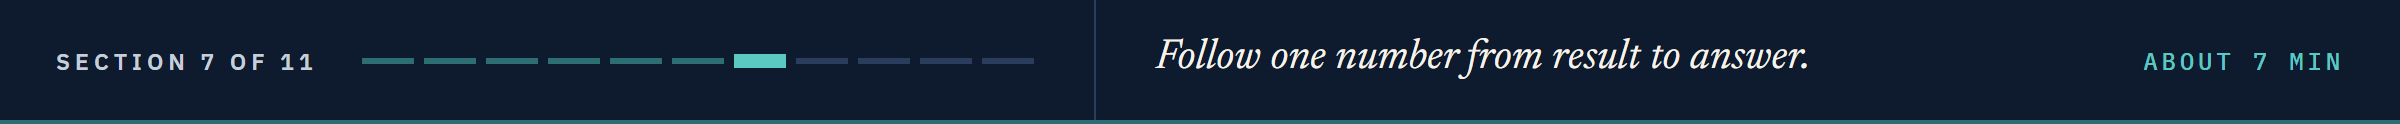

# The DTS Question

**Predict 3**

The DTS question gives the bond's terms and its OAS, 147 bp.
`dts` takes a spread duration and a spread; no tool takes a bond's terms and returns its DTS.
Q. Sketch the tool requests the saved run sends, in order, with their arguments.

## The Run

In [36]:
# the DTS question, all seven tools offered
run_dts = agent_loop(client, QUESTIONS["dts"], TOOLS, SCHEMAS)
print(trace_table(run_dts)[["step", "tool", "arguments", "prompt_tokens"]].to_string(index=False))

 step            tool                                                                            arguments  prompt_tokens
    1 spread_duration {"settlement":"2026-09-30","maturity":"2032-06-18","coupon_pct":7,"yield_pct":5.606}           1076
    2             dts                                   {"spread_duration_years":4.626971,"spread_bp":147}           1165
    3                                                                                                                1237


In [37]:
# agent answer
print(run_dts["replies"][-1].choices[0].message.content)

As of 2026-09-30, the DTS (duration times spread) of bond 99080CAE8, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield and an OAS of 147 bp, is approximately 680.165 years times basis points. The spread duration in years is approximately 4.627.


Two tool requests, then the answer: check your Predict 3.

The second request's `spread_duration_years` is the first result, 4.626971, to the last digit; its 147 is the question's.

## One Number's Path

In [38]:
# every message of the run that holds the spread duration (4.62...) or the DTS (680.16...)
for k, message in enumerate(run_dts["messages"]):
    text = message["content"] or message["tool_calls"][0]["function"]["arguments"]
    if "4.62" in text or "680.16" in text:
        print(k, message["role"], "|", text)

3 tool | {"spread_duration_years": 4.626971, "tool_call_id": "call_RtyKLWwHoj6bYlggE8UPAihf"}
4 assistant | {"spread_duration_years":4.626971,"spread_bp":147}
5 tool | {"dts_years_bp": 680.164737, "tool_call_id": "call_4Bfb4qYtc8O7ybKyX6iMasji"}
6 assistant | As of 2026-09-30, the DTS (duration times spread) of bond 99080CAE8, a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield and an OAS of 147 bp, is approximately 680.165 years times basis points. The spread duration in years is approximately 4.627.


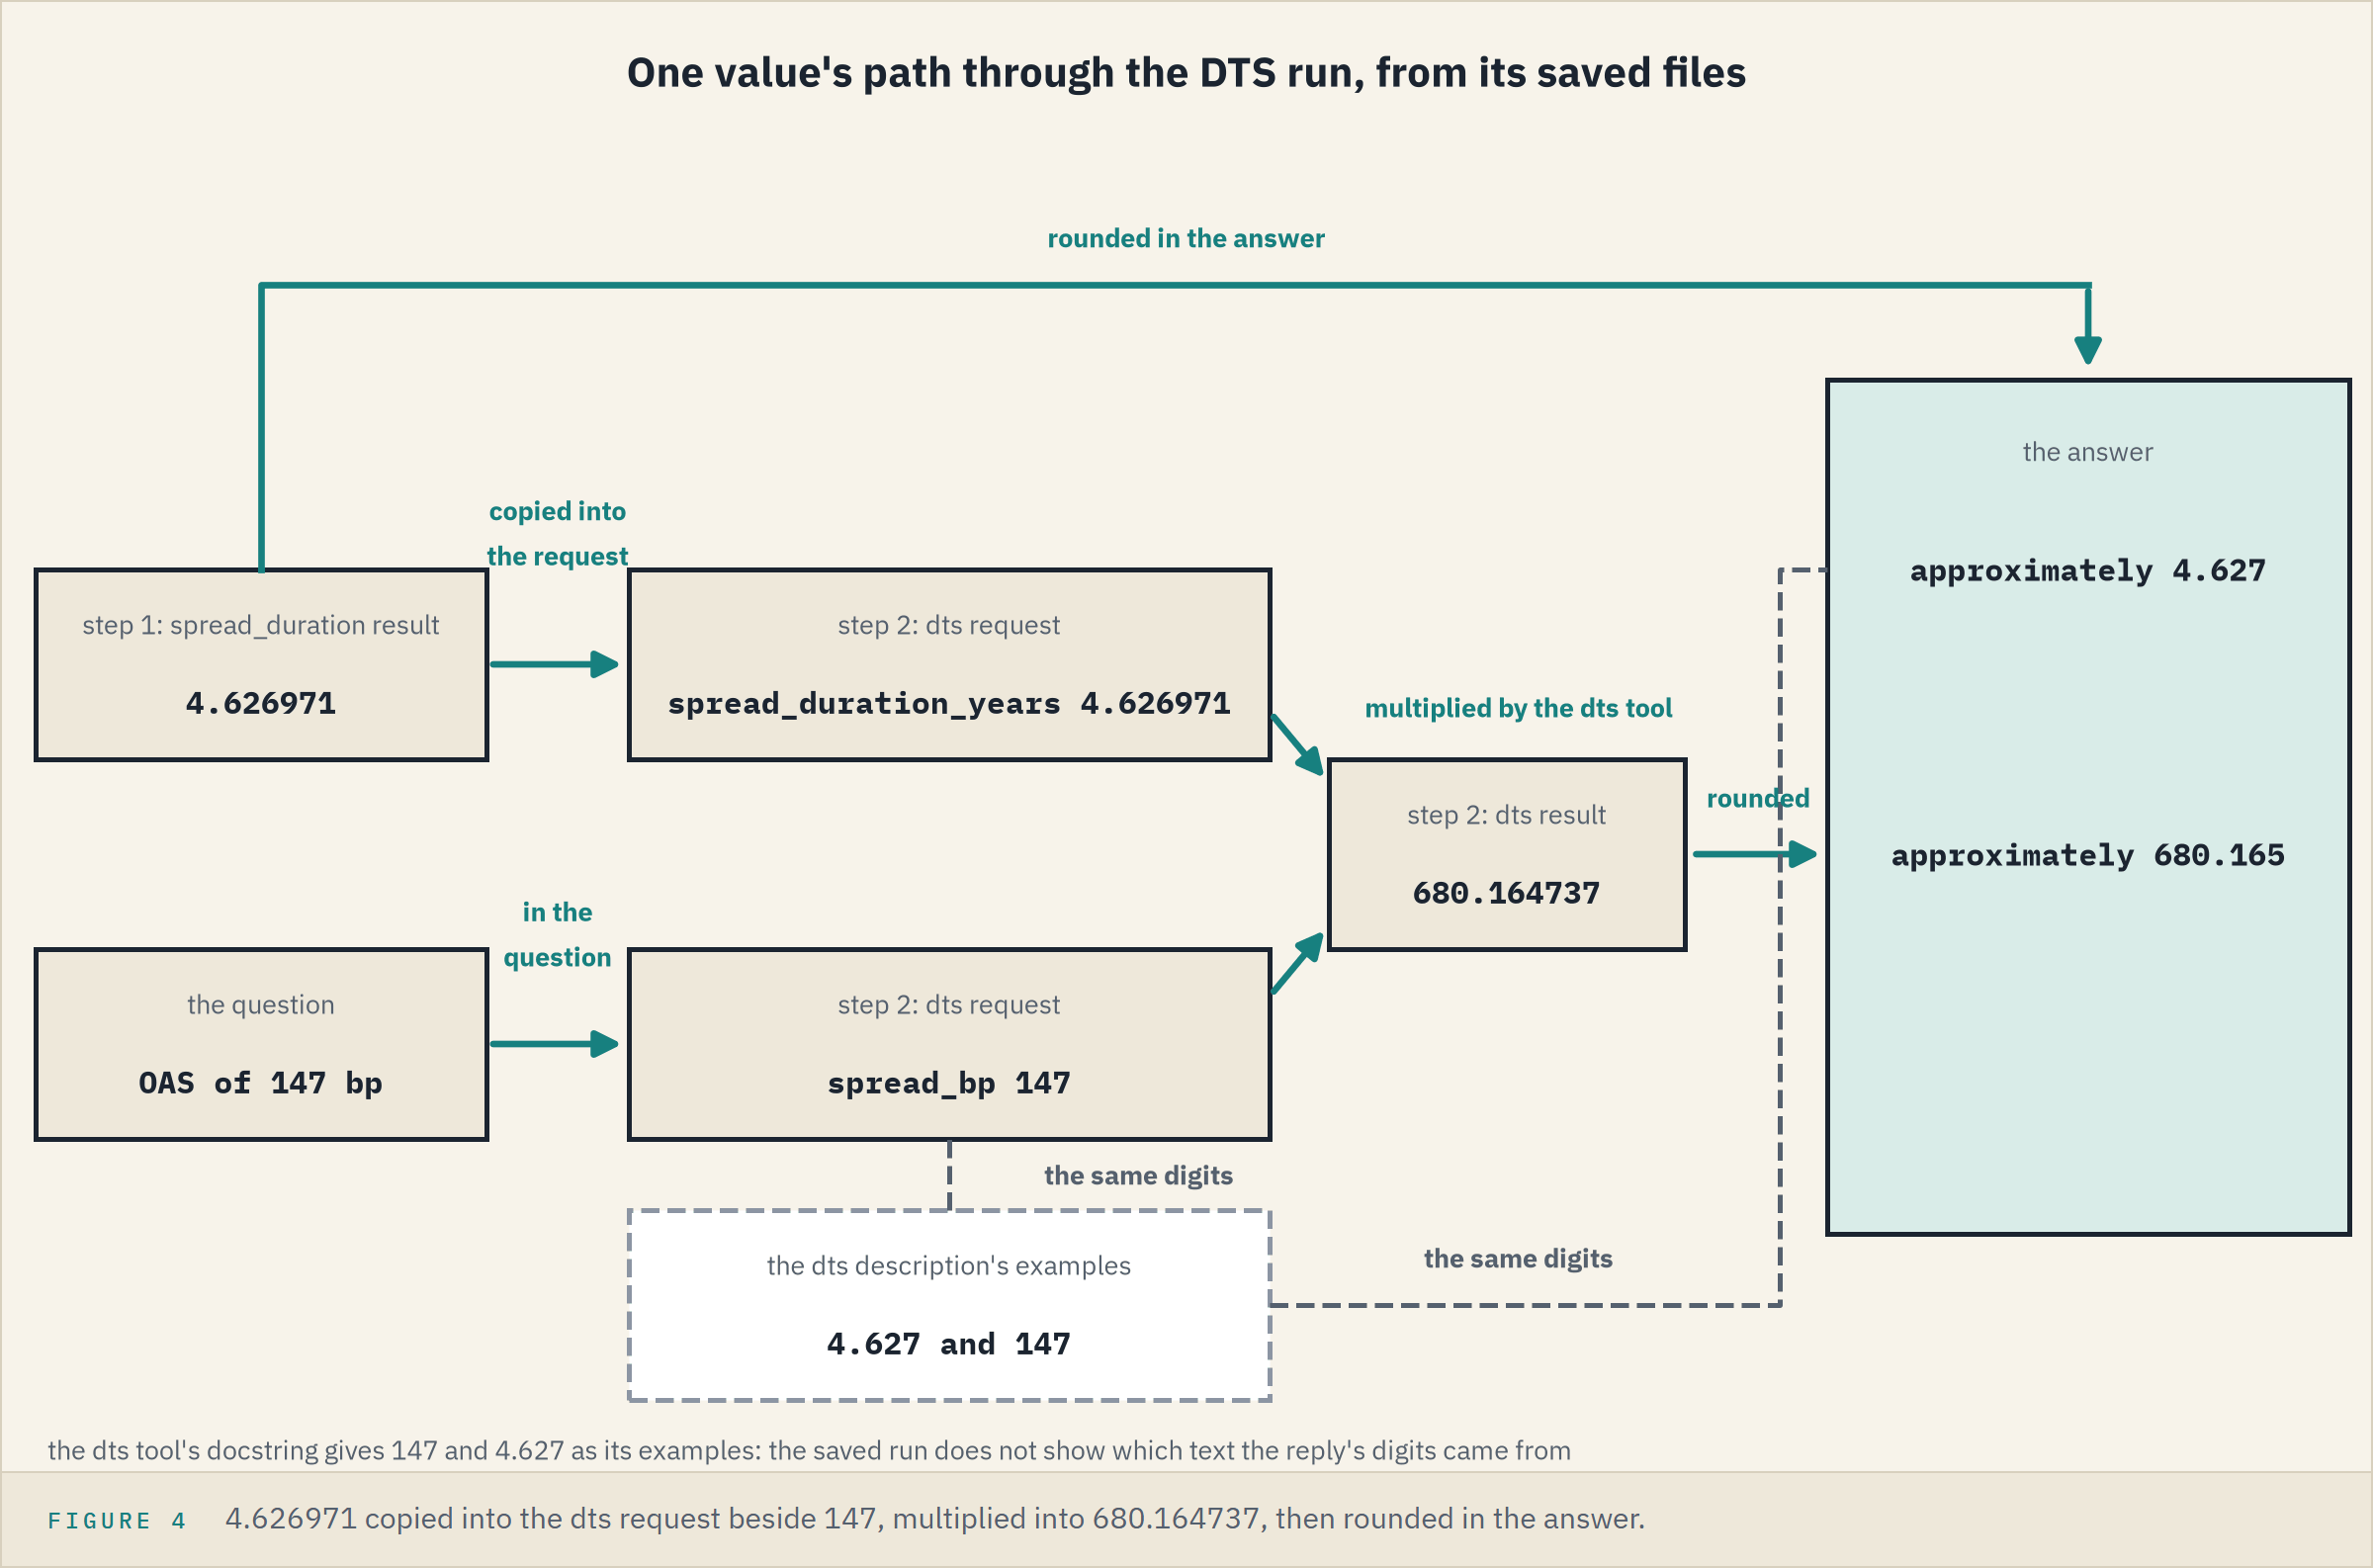

A **chain of values** draws one value at each place it is written in a run, and labels each edge with what moved it.

No line of your code copied 4.626971 into the `dts` request: the model's reply named it as an argument, and your `dts` tool did the multiplying.

The `dts` description's examples, 4.627 and 147, are the same digits as the answer's 4.627 and the question's 147: the saved run does not show which text the reply's digits came from.

## The Six Runs at a Glance

The price is Day 1's: the provider's list price for `gpt-4.1-mini`, from [OpenAI's pricing page](https://developers.openai.com/api/docs/pricing), read 2026-10-08.

In [39]:
# the six runs side by side: requests, tool requests, tokens, and US$ at Day 1's list price
runs["dts"] = run_dts
PRICE_PER_MILLION = {"prompt": 0.40, "completion": 1.60}
rows = []
for name, run in runs.items():
    trace = trace_table(run)
    rows.append({"run": name, "requests": len(trace), "tool_requests": int((trace["tool"] != "").sum()),
                 "first_prompt": int(trace["prompt_tokens"][0]), "prompt_tokens": int(trace["prompt_tokens"].sum()),
                 "completion_tokens": int(trace["completion_tokens"].sum())})
six = pd.DataFrame(rows).set_index("run")
six["usd"] = (six["prompt_tokens"] * PRICE_PER_MILLION["prompt"] + six["completion_tokens"] * PRICE_PER_MILLION["completion"]) / 1_000_000
six

,requests,tool_requests,first_prompt,prompt_tokens,completion_tokens,usd
run,,,,,,
price,2,1,1062,2211,109,0.001059
yield,2,1,1067,2224,139,0.001112
accrued,2,1,1054,2196,99,0.001037
duration,2,1,1074,2239,125,0.001096
dv01,2,1,1076,2239,143,0.001124
dts,3,2,1076,3478,159,0.001646


In [40]:
# the six runs in all
print(six[["requests", "tool_requests", "prompt_tokens", "completion_tokens"]].sum().to_dict(), "| US$", round(six["usd"].sum(), 7))

{'requests': 13, 'tool_requests': 7, 'prompt_tokens': 14587, 'completion_tokens': 774} | US$ 0.0070732


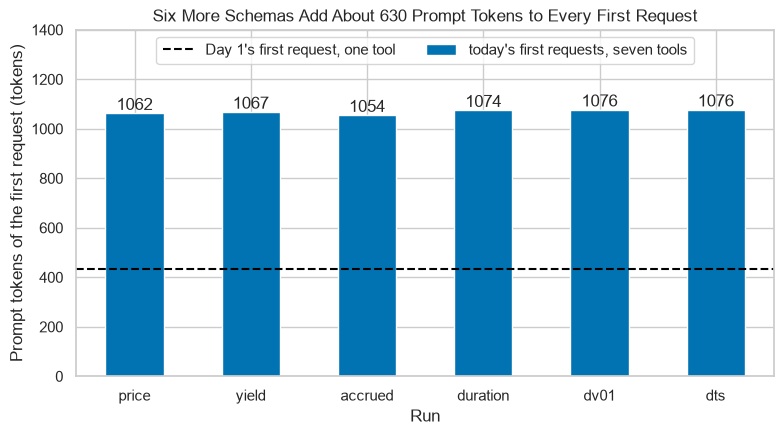

In [41]:
# each run's first request against Day 1's, which offered one tool
ax = six["first_prompt"].plot.bar(rot=0, figsize=(9, 4.5), label="today's first requests, seven tools")
ax.axhline(day1_saved["response"]["usage"]["prompt_tokens"], ls="--", color="black", label="Day 1's first request, one tool")
ax.bar_label(ax.containers[0])
ax.set_ylim(0, 1400)
ax.set_xlabel("Run")
ax.set_ylabel("Prompt tokens of the first request (tokens)")
ax.set_title("Six More Schemas Add About 630 Prompt Tokens to Every First Request")
ax.legend(loc="upper center", ncols=2)
plt.show()

The six schemas Day 1 did not send add about 4,100 characters, and 622 to 644 prompt tokens to every first request.

The first requests differ by 22 tokens at most: only the question changes between them.

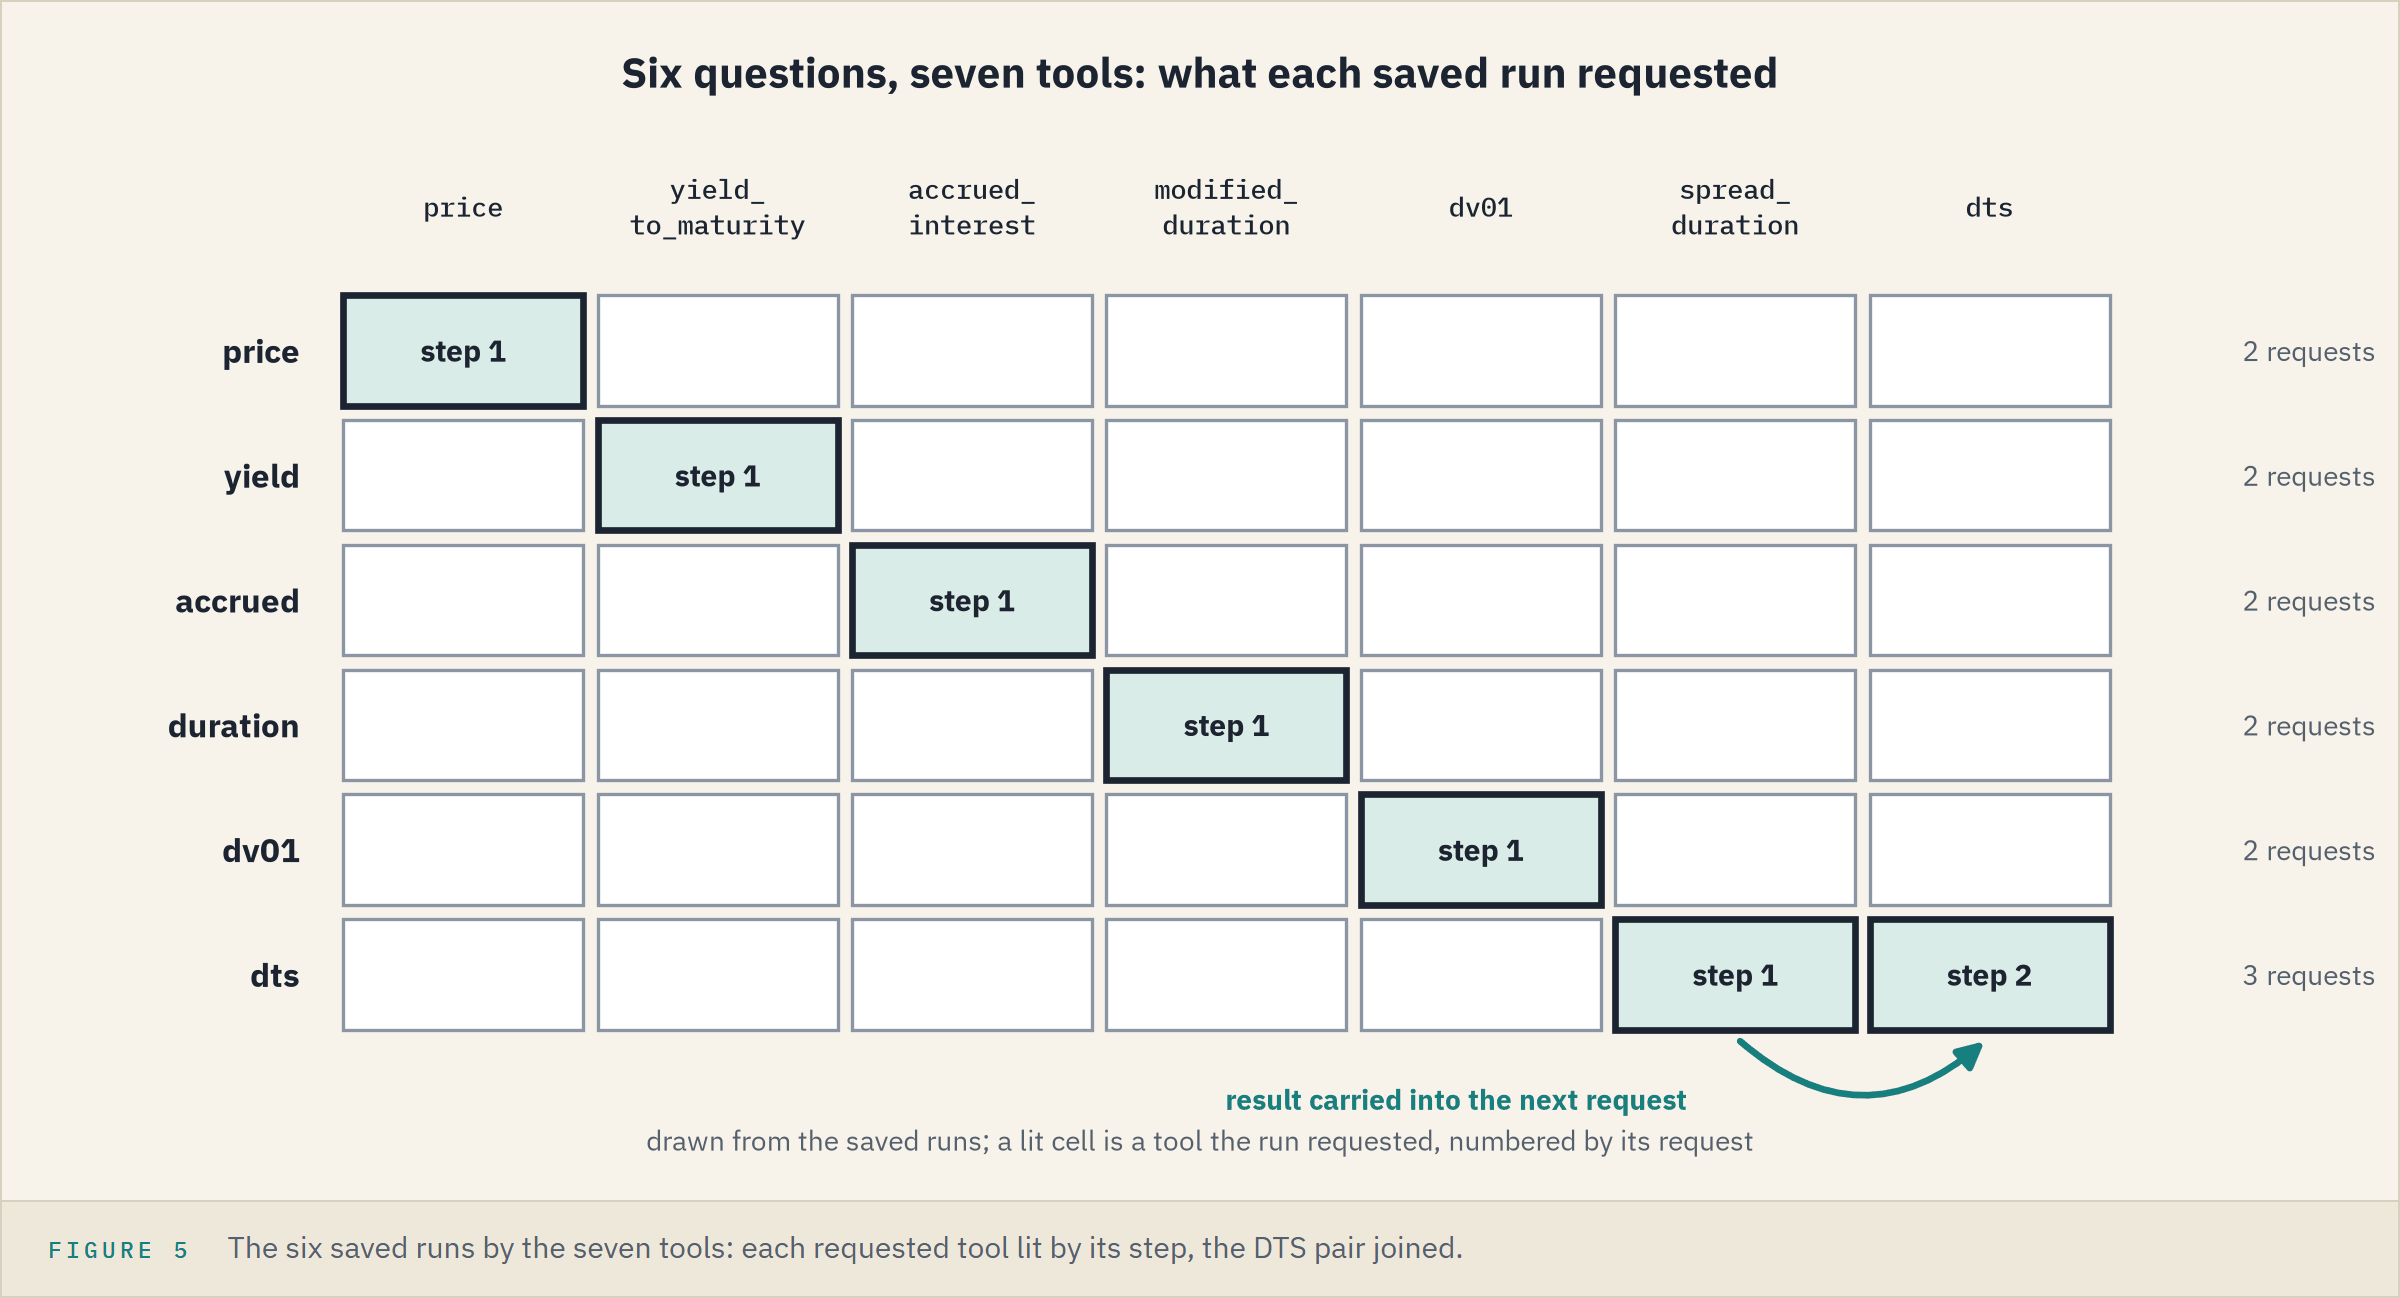

Thirteen requests, seven tool requests, and no tool requested that a question did not need.

> STORY: In February 2023 Timo Schick and seven co-authors posted "Toolformer: Language Models Can Teach Themselves to Use Tools" to arXiv.
> Its abstract describes language models trained to write requests to simple tools into their own text: a calculator, a question-answering system, two search engines, a translation system and a calendar.
> The tools did the arithmetic and the lookups, and the text carried their results.
> Today's toolkit is the same division of labour, written by hand: the desk's functions compute, and the model's reply names which one to run.
> The paper itself was not read for this course.
> Source: arXiv record 2302.04761, https://arxiv.org/abs/2302.04761

**In every saved run the first tool request named the tool the question needs, and the tools did every computation.**

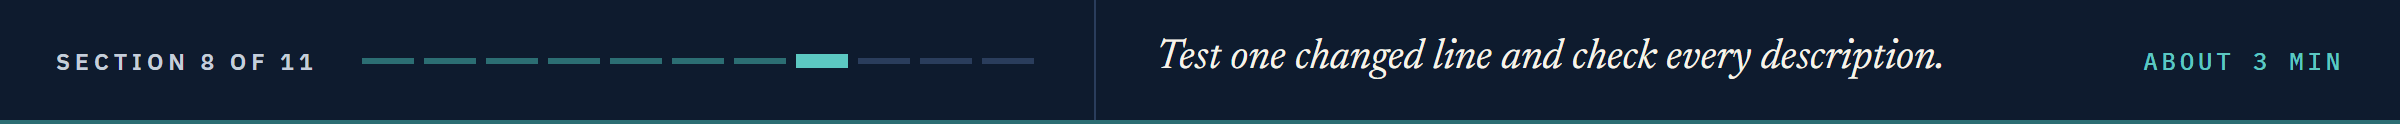

# Rewriting One Description

## One Line Changed

A desk that keeps yields as decimals might rewrite the `yield_pct` line.

In [42]:
# the yield_pct line as written, and a rewrite that asks for a decimal
OLD = "the yield to maturity in percent, 5.06 for 5.06%."
NEW = "the yield to maturity as a decimal, 0.0506 for 5.06%."
# tool_schema builds a new dict every time it runs, so SCHEMAS is left as it was
rewritten_dv01 = tool_schema(dv01)
rewritten_dv01["function"]["parameters"]["properties"]["yield_pct"]["description"] = NEW
SCHEMAS_REWRITTEN = SCHEMAS[:4] + [rewritten_dv01] + SCHEMAS[5:]
print("SCHEMAS keeps the old line:", SCHEMAS[4]["function"]["parameters"]["properties"]["yield_pct"]["description"] == OLD)

SCHEMAS keeps the old line: True


The `dv01` function is unchanged: it still reads `yield_pct` in percent.

Only the words the model reads have changed.

**Predict 4**

The rewritten line asks for the yield as a decimal, 0.0506 for 5.06%; the question still writes "a 6.393% yield".
Q. What `yield_pct` does the saved run's tool request send, and what does `dv01` return?

## The DV01 Question Again

In [43]:
# the DV01 question with the rewritten description, beside the run as written
run_rewritten = agent_loop(client, QUESTIONS["dv01"], TOOLS, SCHEMAS_REWRITTEN)
for label, run in [("as written", runs["dv01"]), ("rewritten", run_rewritten)]:
    first = trace_table(run).iloc[0]
    print(f"{label}: yield_pct {json.loads(first['arguments'])['yield_pct']}, {first['result']}, {first['prompt_tokens']} prompt tokens")

as written: yield_pct 6.393, {"dv01_per_100": 0.127083, "tool_call_id": "call_SGeBarWguVBJLj7faeZp1Ql3"}, 1076 prompt tokens
rewritten: yield_pct 6.393, {"dv01_per_100": 0.127083, "tool_call_id": "call_tk3ei9gBXyZcQAPwJLjgljf0"}, 1078 prompt tokens


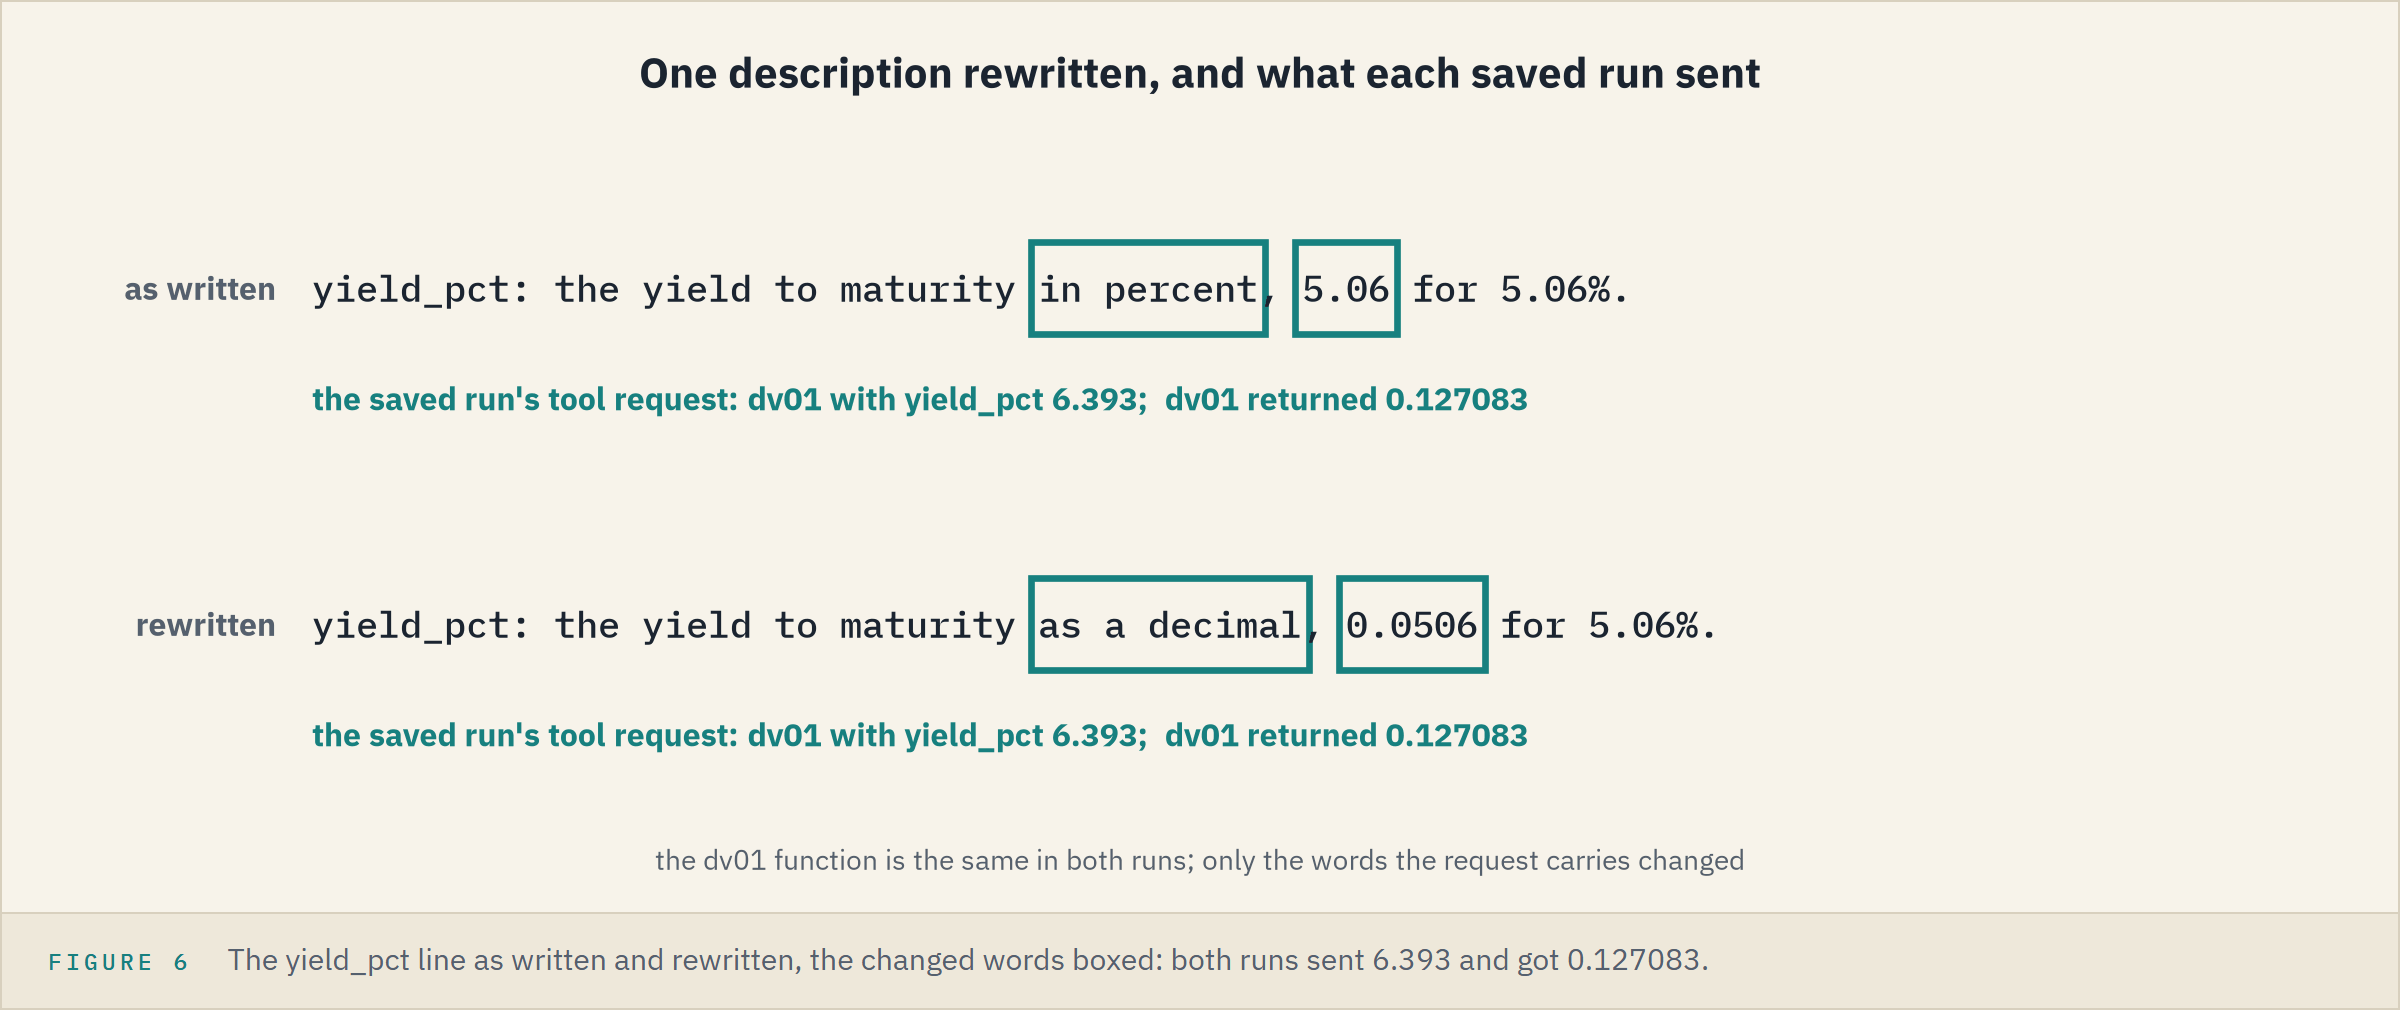

### Interpretation of the Rewrite

Both requests sent 6.393 and got 0.127083 back: check your Predict 4.

The name `yield_pct` and the question's "6.393%" still said percent, and the saved run does not show which words the reply followed.

A wrong description can pass every run you look at: a check on its words finds it.

## A Check on the Descriptions

In [44]:
# every argument whose name ends in _pct (str.endswith, Course 3's startswith) must say "in percent" in its description
def unit_problems(schemas):
    """The (tool, argument) pairs whose name ends in _pct and whose description does not say in percent."""
    return [(s["function"]["name"], name) for s in schemas for name, p in s["function"]["parameters"]["properties"].items()
            if name.endswith("_pct") and "in percent" not in p["description"]]


print("as written:", unit_problems(SCHEMAS), "| rewritten:", unit_problems(SCHEMAS_REWRITTEN))

as written: [] | rewritten: [('dv01', 'yield_pct')]


The check reads every description in a moment, with no request.

**Read descriptions with code, as well as running them.**

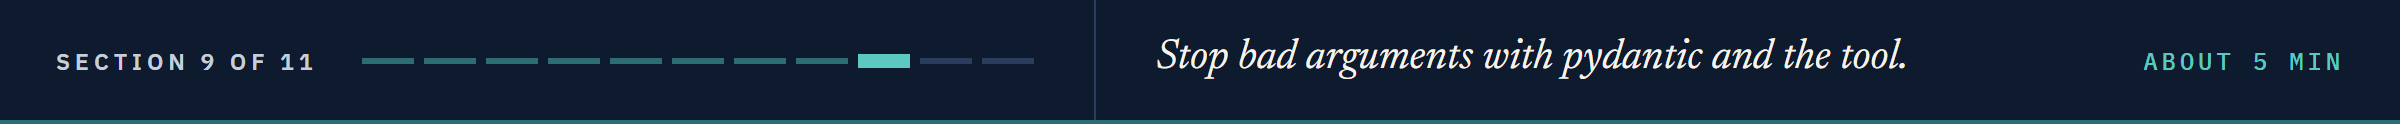

# Checking Arguments Before a Tool Runs

## Seven Sets of Arguments, Written by Hand

The cases are written by hand to test the checks: no saved run sent any of them.

In [45]:
# 99033HAF2's terms as a tool request carries them, then six ways a request could get them wrong
terms = {"settlement": "2026-09-30", "maturity": "2050-02-26", "coupon_pct": 7.0, "yield_pct": 6.393}
CASES = {"ISO text": terms, "2026/09/30": terms | {"settlement": "2026/09/30"}, "coupon 0.07": terms | {"coupon_pct": 0.07},
         "yield '6.393'": terms | {"yield_pct": "6.393"}, "yield 'five'": terms | {"yield_pct": "five"},
         "no maturity": {k: v for k, v in terms.items() if k != "maturity"}, "2026-09-31": terms | {"settlement": "2026-09-31"}}

In [46]:
# each case as an assistant message (Day 2's shape), through run_tools with dv01 as written
def asking_dv01(arguments):
    """An assistant message holding one dv01 tool request with these arguments."""
    return {"role": "assistant", "content": None, "tool_calls": [
        {"id": "call_example", "type": "function", "function": {"name": "dv01", "arguments": json.dumps(arguments)}}]}


for case, arguments in CASES.items():
    print(case, "|", run_tools(asking_dv01(arguments), {"dv01": dv01})[0]["content"])

ISO text | {"dv01_per_100": 0.127083, "tool_call_id": "call_example"}
2026/09/30 | {"error": "Invalid isoformat string: '2026/09/30'", "tool_call_id": "call_example"}
coupon 0.07 | {"error": "coupon_pct 0.07 is below 0.5: write the coupon in percent, 5.0 for a 5% coupon", "tool_call_id": "call_example"}
yield '6.393' | {"error": "unsupported operand type(s) for -: 'str' and 'float'", "tool_call_id": "call_example"}
yield 'five' | {"error": "unsupported operand type(s) for -: 'str' and 'float'", "tool_call_id": "call_example"}
no maturity | {"error": "dv01() missing 1 required positional argument: 'maturity'", "tool_call_id": "call_example"}
2026-09-31 | {"error": "day is out of range for month", "tool_call_id": "call_example"}


Every case comes back as a result, as Day 2's `run_tools` promises.

"6.393" and "five" fail inside the arithmetic, with a message about `-` that names no argument.

## Pydantic's `validate_call`

`pydantic.validate_call(f)` wraps a function so each argument is checked against its type hint before the function runs; a wrong one raises `pydantic.ValidationError`.

In [47]:
# pydantic comes with openai (the client cell installs it in Colab); issubclass asks whether one kind of error is a kind of another
import pydantic

checked = pydantic.validate_call(dv01)
print("the same schema:", tool_schema(checked) == tool_schema(dv01), "| a kind of ValueError:", issubclass(pydantic.ValidationError, ValueError))

the same schema: True | a kind of ValueError: True


The wrapper keeps the name, the hints and the docstring, so the request is unchanged.

A `ValidationError` is a `ValueError`, so Day 2's `run_tools` sends it back as words.

In [48]:
# the seven cases through the checked dv01: which check stopped each, or the result
for case, arguments in CASES.items():
    content = json.loads(run_tools(asking_dv01(arguments), {"dv01": checked})[0]["content"])
    stopped, said = "result", content.get("error", content.get("dv01_per_100"))
    if "error" in content:
        stopped = "the tool"
    if str(said).startswith("1 validation error"):
        # pydantic's message: a count of errors, the field, then what was wrong and a [type=...] note
        stopped, said = "validate_call", " / ".join(line.strip() for line in said.splitlines()[1:3]).split(" [")[0]
    print(case, "|", stopped, "|", said)

ISO text | result | 0.127083
2026/09/30 | the tool | Invalid isoformat string: '2026/09/30'
coupon 0.07 | the tool | coupon_pct 0.07 is below 0.5: write the coupon in percent, 5.0 for a 5% coupon
yield '6.393' | result | 0.127083
yield 'five' | validate_call | yield_pct / Input should be a valid number, unable to parse string as a number
no maturity | validate_call | maturity / Missing required argument
2026-09-31 | the tool | day is out of range for month


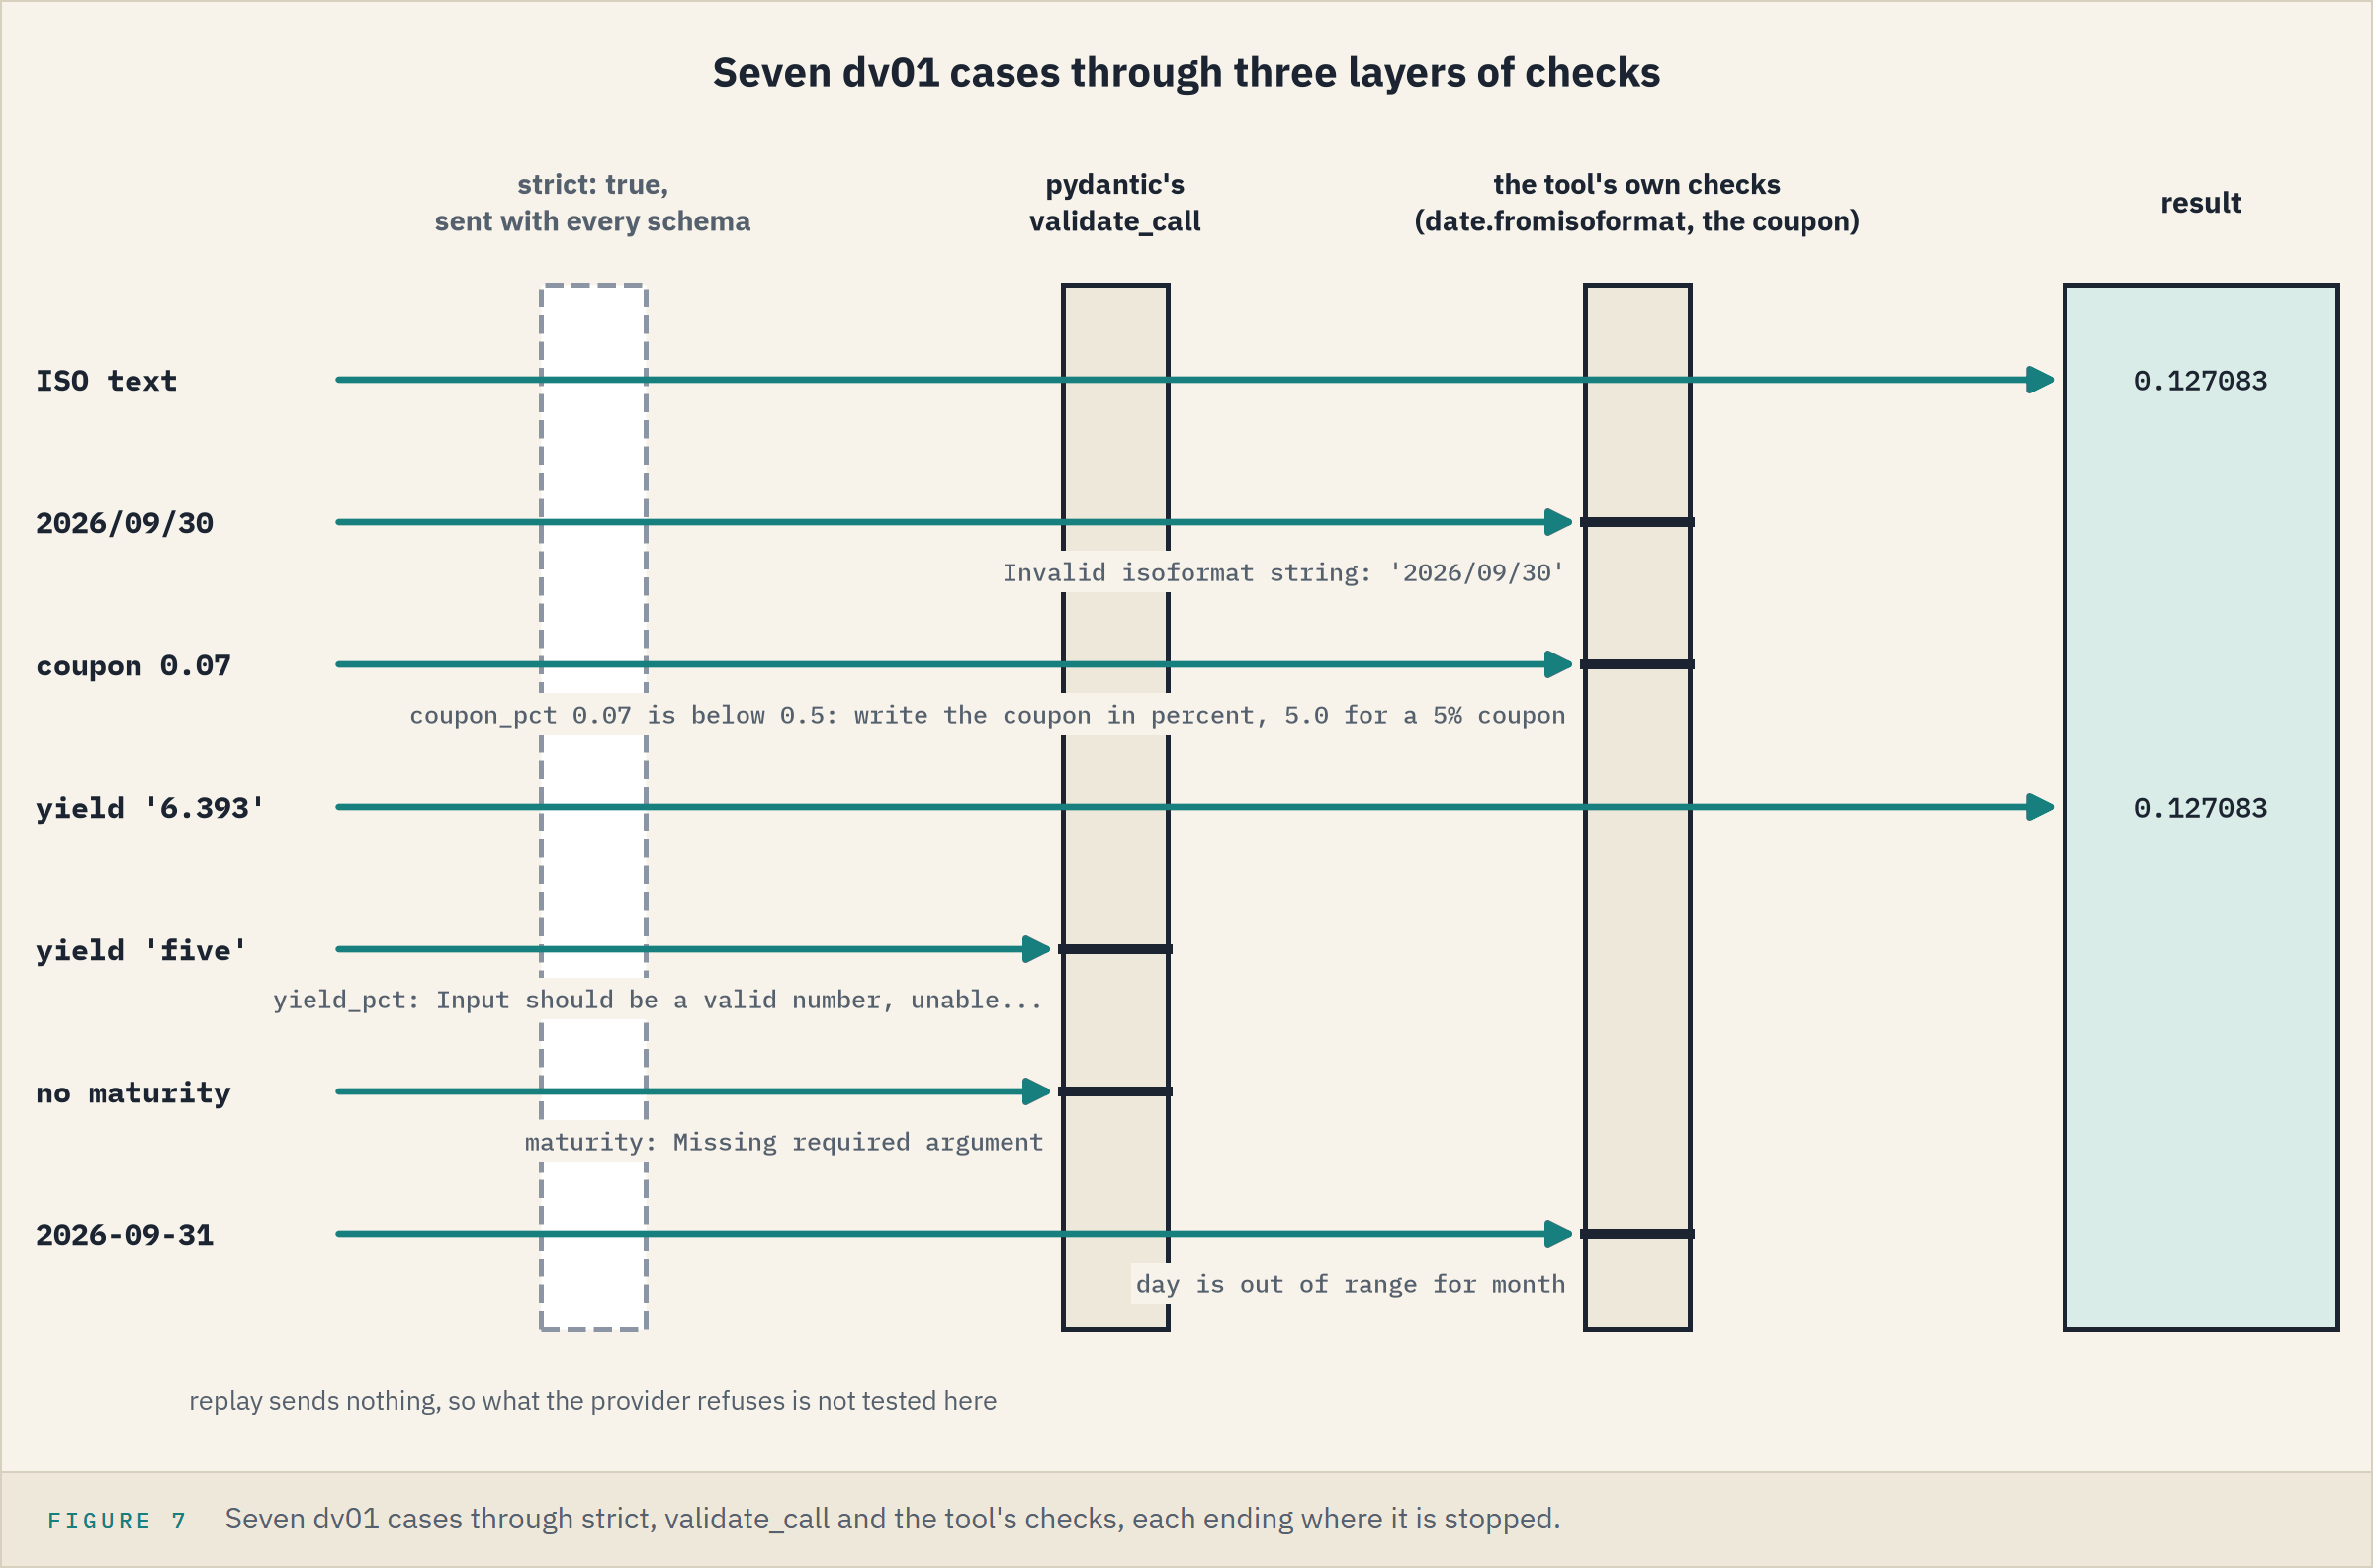

**Layered checks** draw each check as a slice in the order it runs, and each case as an arrow that ends where it is stopped.

`validate_call` stops "five" and the missing maturity, and names the field; it turns "6.393" into a number, which runs.

To a type check a date is only text and 0.07 is a number, so the two bad dates and the decimal coupon pass it and stop in the tool.

Pydantic names the field, and the tool checks the meaning.

## The Checked Toolkit

In [49]:
# every tool checked the same way; the schemas are unchanged, so the saved runs still answer
CHECKED = {name: pydantic.validate_call(f) for name, f in TOOLS.items()}
run_checked = agent_loop(client, QUESTIONS["dv01"], CHECKED, SCHEMAS)
print("the same schemas:", [tool_schema(f) for f in CHECKED.values()] == SCHEMAS,
      "| the same run:", run_checked["messages"] == runs["dv01"]["messages"])

the same schemas: True | the same run: True


The DV01 question through the checked tools replays the same two saved files, message for message.

**From here on, the raw loop runs the checked tools.**

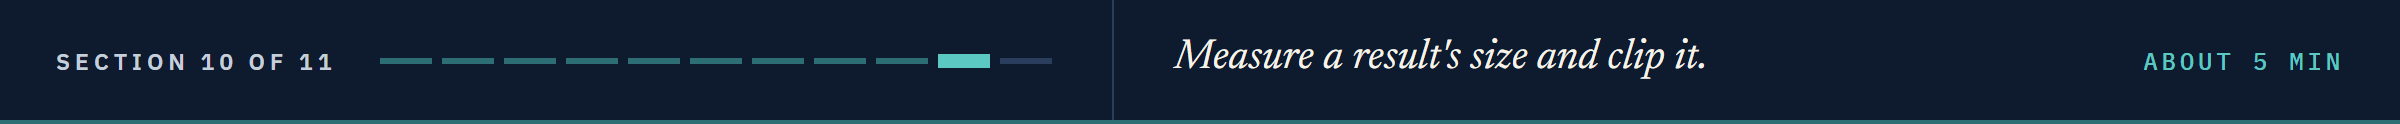

# Keeping Results Short

## What a Result Adds

In [50]:
# the characters of each tool message in today's six runs
print({name: [len(m["content"]) for m in run["messages"] if m["role"] == "tool"] for name, run in runs.items()})

{'price': [84], 'yield': [72], 'accrued': [78], 'duration': [86], 'dv01': [75], 'dts': [84, 77]}


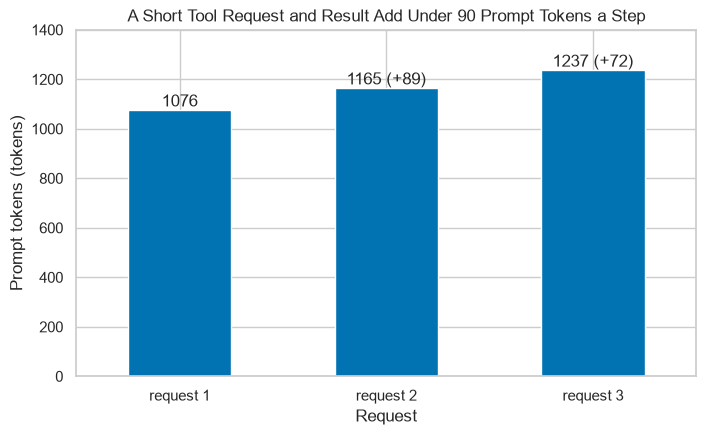

In [51]:
# the DTS run's prompt tokens, request by request, with what each added to the one before (.diff(), Course 1)
dts_tokens = trace_table(run_dts)["prompt_tokens"]
added = dts_tokens.diff()
ax = dts_tokens.plot.bar(rot=0, figsize=(8, 4.5))
ax.bar_label(ax.containers[0], labels=[f"{t}" if k == 0 else f"{t} (+{added[k]:.0f})" for k, t in enumerate(dts_tokens)])
ax.set_ylim(0, 1400)
ax.set_xticks(range(3), ["request 1", "request 2", "request 3"])
ax.set_xlabel("Request")
ax.set_ylabel("Prompt tokens (tokens)")
ax.set_title("A Short Tool Request and Result Add Under 90 Prompt Tokens a Step")
plt.show()

Each step resends a tool request and a result of under 90 characters, and adds under 90 prompt tokens (Day 2's growth).

## A Result Too Long to Resend

In [52]:
# a result no question today needs: the market value in US$ of all 200 bonds, as one dictionary written as JSON
every_bond = dict(zip(holdings["cusip"], holdings["market_value"]))
whole = json.dumps(every_bond, sort_keys=True)
print(len(whole), "characters |", whole[:70])

4768 characters | {"99001BAA4": 2747552.5, "99001BAF3": 463430.0, "99002CAA1": 246490.0,


As a tool result it would ride in every later request of the run, about 60 times the size of a result today.

## `clip_result`

In [53]:
# keep the first characters, and end with a note of how much there was
def clip_result(text, max_chars=2000):
    """The text whole if it fits in max_chars, else its start and a note of its full length."""
    if len(text) <= max_chars:
        return text
    note = f" [cut: {len(text):,} characters in all]"
    return text[:max_chars - len(note)] + note


clipped = clip_result(whole)
print(len(clipped), "characters | whole entries kept:", clipped.count(", "), "|", clipped[-50:])

2000 characters | whole entries kept: 82 | , "99055DAD9": 3824 [cut: 4,768 characters in all]


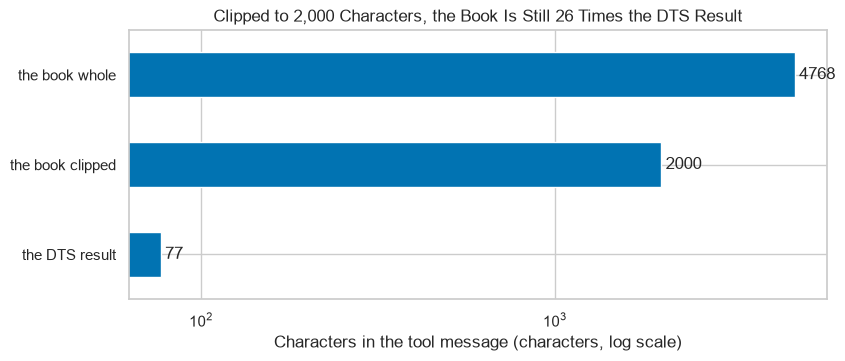

In [54]:
# one of today's results, the book whole and the book clipped, on a log axis (Course 2's set_xscale)
sizes = pd.Series({"the DTS result": len(run_dts["messages"][-2]["content"]), "the book clipped": len(clipped),
                   "the book whole": len(whole)})
ax = sizes.plot.barh(figsize=(9, 3.5))
ax.set_xscale("log")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlabel("Characters in the tool message (characters, log scale)")
ax.set_title("Clipped to 2,000 Characters, the Book Is Still 26 Times the DTS Result")
plt.show()

The note says the result is partial and how much was left out.

A clipped result is partial: the cut characters never reach the model.

## Your Turn: Set the Limit

Drag the slider: each position clips the book at `max_chars` and counts the bonds kept whole.

In [55]:
# your turn: drag max_chars and watch how much of the book is kept
def clip_view(max_chars=2000):
    """Clip the book's market values at max_chars and draw the characters kept against the whole."""
    kept = clip_result(whole, max_chars)
    # each ", " closes one whole entry; text that was not cut also holds its last entry (True counts as 1)
    entries = kept.count(", ") + (kept == whole)
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.barh(["kept", "whole"], [len(kept), len(whole)])
    ax.set_xlim(0, 5200)
    ax.set_xlabel("Characters (characters)")
    ax.set_title(f"max_chars={max_chars}: {entries} of 200 Bonds Kept Whole")
    plt.show()


interact(clip_view, max_chars=(500, 5000, 250));

interactive(children=(IntSlider(value=2000, description='max_chars', max=5000, min=500, step=250), Output()), …

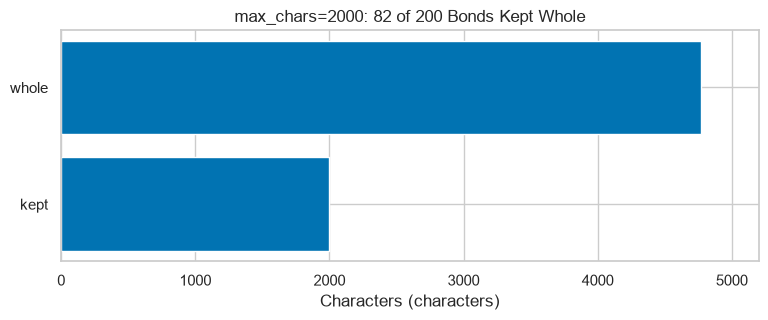

In [56]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
clip_view(2000)

Each extra 1,000 characters keeps about 40 more bonds; past 4,768 nothing is cut.

A limit is a choice of what the model never reads, so a tool that must clip says so in its result.

**Keep results short, and say when one was cut.**

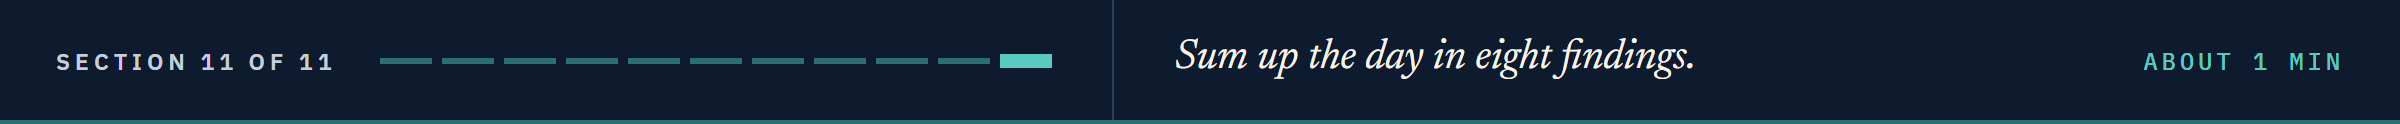

# Insights and Conclusion

The schema read from `dv01`'s docstring equals the one Day 1 wrote by hand.

Six more schemas than Day 1 sent add about 630 prompt tokens to every first request.

In all six saved runs the first tool request named the tool the question needs, on the question's terms.

Four of six answers round the tool's value, none wrong in a digit.

One result travelled into the next tool request, and the tool did the multiplying.

One rewritten description changed no argument, and a check on the descriptions caught it.

Pydantic names the field, and the tool checks the meaning.

4,768 characters of the book clipped to 2,000, with a note of the cut.

**A toolkit is only as good as the words its functions carry.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Write a bond function as a tool, with type hints and an `Args:` docstring in units.
* Read a tool's schema from its function.
* Offer several tools at once, and read which tool each run requested.
* Follow one number through a run.
* Test a change to a tool description, and check descriptions with code.
* Check a tool's arguments with `pydantic.validate_call` before it runs.
* Measure what schemas and results add to a request, and clip a long result.

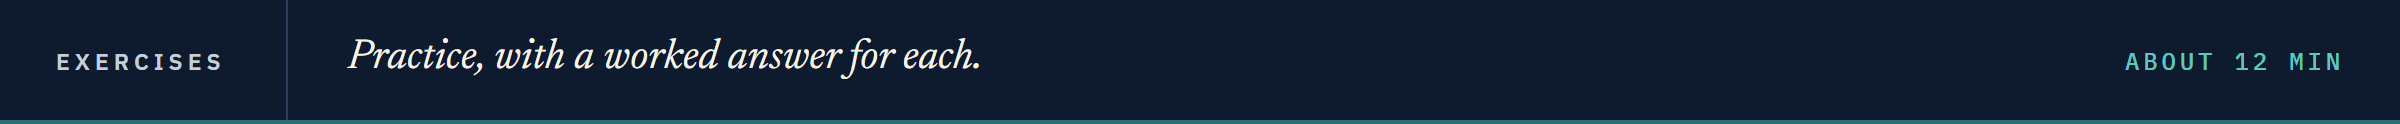

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [57]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**An Eighth Tool**

Q. Write the body of `convexity` under its docstring, add it to the toolkit, and run `EX1_QUESTION` with the eight tools.
The course recorded it with the sum form, which Course 2's central difference matches only to 3 decimals here: with `t = (w + k) / 2` in years and `rate = yield_pct / 200`, each flow adds `flow * t * (t + 0.5) / (1 + rate) ** (2 * t + 2)`, and the sum over the dirty price is the convexity.
Store the tools the run requested, as a list, and the value `convexity` returned as a list in `ex1_run`, for example `[["price"], 99.5]`.
Q. What did the eighth schema add to the first request?

In [58]:
# the eighth tool: its docstring as the course recorded it; write the body
def convexity(settlement: str, maturity: str, coupon_pct: float, yield_pct: float) -> dict:
    """The convexity in years squared of a fixed-coupon bond (semiannual coupons, 30/360), from its yield.

    Args:
        settlement: the settlement date as YYYY-MM-DD, for example 2026-10-02.
        maturity: the maturity date as YYYY-MM-DD.
        coupon_pct: the annual coupon in percent, 5.0 for a 5% coupon.
        yield_pct: the yield to maturity in percent, 5.06 for 5.06%.
    """
    # your code here
    return {"convexity_years_squared": ...}


EX1_QUESTION = ("As of 2026-09-30, what is the convexity in years squared of bond 99033HAF2 of the synthetic holdings, "
                "a 7.000% bullet settling 2026-09-30 and maturing 2050-02-26 at a 6.393% yield?")

# your code here
ex1_run = ...

In [59]:
check("Exercise 1 the tools requested and the convexity", ex1_run, [["convexity"], 206.928841])

Exercise 1 the tools requested and the convexity: not attempted yet


### Exercise 2

**A Question No Tool Answers**

Q. Run `EX2_QUESTION` with the seven tools and read its answer.
Store its stop, its number of tool requests, and the names of the tools whose docstring holds "147" (`inspect.getdoc`) as a list in `ex2_run`.
Q. Run Day 1's number check on the answer: which numbers are in neither the question nor a tool result?

In [60]:
# the OAS of a bond: no tool returns a spread
EX2_QUESTION = ("As of 2026-09-30, what is the option-adjusted spread in bp of bond 99080CAE8 of the synthetic holdings, "
                "a 7.000% bullet settling 2026-09-30 and maturing 2032-06-18 at a 5.606% yield?")

# your code here
ex2_run = ...

In [61]:
check("Exercise 2 the stop, the tool requests and the tools that write 147", ex2_run, ["answer", 0, ["dts"]])

Exercise 2 the stop, the tool requests and the tools that write 147: not attempted yet


### Exercise 3

**Count a Tool's Requests**

Q. Write `tool_count(run, name)`, a plain function with a one-line docstring: how many tool requests of a run named the tool `name`.
Store `[tool_count(run_dts, n) for n in ("spread_duration", "dts", "price")]` in `ex3_counts`.
Q. What does a count of 0 say about a tool that was offered?

In [62]:
# your code here
ex3_counts = ...

In [63]:
check("Exercise 3 the DTS run's requests by tool", ex3_counts, [1, 1, 0])

Exercise 3 the DTS run's requests by tool: not attempted yet


### Exercise 4: AI check

**A Wrapper That Never Fails**

You asked an AI assistant for a wrapper that keeps the loop going whatever a tool does.
This came back.
It runs.
`keep_going(function)` returns a new function, `run_tool`, that runs the tool inside a `try`; `**arguments` in a `def` gathers every keyword argument into one dictionary.

In [64]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def keep_going(function):
    """Wrap a tool so a failure never stops the loop; a failure is never a number."""
    def run_tool(**arguments):
        """Run the tool on its arguments."""
        try:
            return function(**arguments)
        # anything that goes wrong becomes a zero, so the agent keeps going
        except Exception:
            return {"value": 0.0}
    return run_tool


# the wrapper on a date that does not exist, and the tool message the next request would carry
BAD_DATE = terms | {"settlement": "2026-09-31"}
print("the model would read:", json.dumps({"tool_call_id": "call_example"} | keep_going(dv01)(**BAD_DATE), sort_keys=True))

the model would read: {"tool_call_id": "call_example", "value": 0.0}


Q. Read the printed line against the docstring, and fix the one wrong idea.
Run your fixed wrapper on `BAD_DATE` and store the text of its error in `ex4_error`.

In [65]:
# your code here
ex4_error = ...

In [66]:
check("Exercise 4 the fixed wrapper's error", ex4_error, "day is out of range for month")

Exercise 4 the fixed wrapper's error: not attempted yet


## Congratulations!

You turned the desk's bond math into seven tools whose descriptions come straight from their own docstrings.
The schema you read from `dv01` matched Day 1's hand-written one to the character, and six saved runs each requested the right tool on the question's terms.
You followed a spread duration from one result into the next request, caught a rewritten description with a line of code, and put pydantic in front of every tool.
Your toolkit now checks what goes in and keeps what comes out short.
Next, in Day 4, the answers stop being free text: every figure arrives in a structure that cites the tool request it came from, and code checks it.

[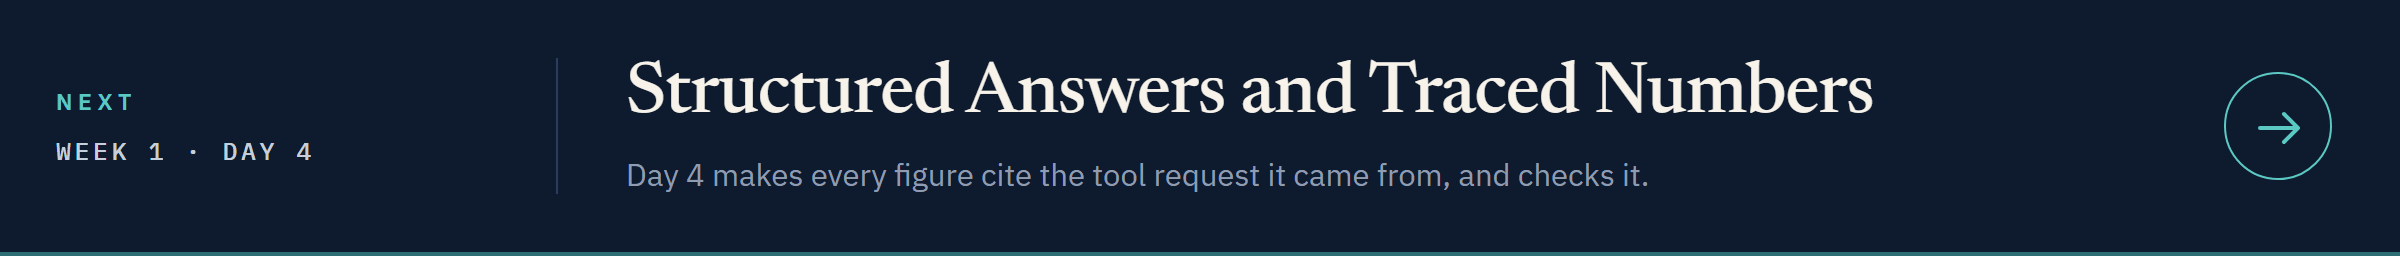](../day4/04_structured_answers_and_traced_numbers.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course08_agentic_ai/week1/day4/04_structured_answers_and_traced_numbers.ipynb)